In [ ]:

# SSIE 501 - Black Box Individual Analysis
# Step 1: Prepare Python tools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python tools loaded successfully!")


Python tools loaded successfully!


In [ ]:

# STEP 2: Create the group's proposed four-region layout

regions = np.zeros((20, 20), dtype=int)

# Region 1
regions[0:5, 0:15] = 1
regions[5:10, 0:5] = 1

# Region 2
regions[0:5, 15:20] = 2
regions[5:10, 5:20] = 2

# Region 3
regions[10:15, 0:15] = 3
regions[15:20, 0:5] = 3

# Region 4
regions[10:15, 15:20] = 4
regions[15:20, 5:20] = 4

# Count and validate the regions
counts = {}

for number in range(1, 5):
    counts[number] = int(np.sum(regions == number))
    print(f"Region {number}: {counts[number]} cells")

print("Total cells:", regions.size)

assert regions.shape == (20, 20)
assert counts == {1: 100, 2: 100, 3: 100, 4: 100}
assert np.all(regions > 0)

print("Region structure validation PASSED")


Region 1: 100 cells
Region 2: 100 cells
Region 3: 100 cells
Region 4: 100 cells
Total cells: 400
Region structure validation PASSED


In [ ]:

# STEP 3: Verify actual group observations
# Source: Group 5 ELN, September 10 experiment
# Transition: Step 77 to Step 78

observations = pd.DataFrame({
    "Cell": ["M1", "N9", "F12"],
    "Before": [0, 4, 3],
    "After": [1, 8, 2]
})

# Calculate each cell's numerical change
observations["Change"] = (
    observations["After"] - observations["Before"]
)

# Add the individual changes
calculated_change = int(observations["Change"].sum())

# Matrix totals reported in the ELN
matrix_before = 1430
matrix_after = 1434

# Calculate the difference independently
reported_change = matrix_after - matrix_before

# Validate the transcription and calculations
assert observations["Cell"].tolist() == ["M1", "N9", "F12"]
assert observations["Before"].tolist() == [0, 4, 3]
assert observations["After"].tolist() == [1, 8, 2]
assert calculated_change == 4
assert reported_change == 4
assert calculated_change == reported_change

print("GROUP OBSERVATIONS:")
display(observations)

print("Calculated change:", calculated_change)
print("Reported matrix change:", reported_change)
print("Arithmetic validation PASSED")


GROUP OBSERVATIONS:


,Cell,Before,After,Change
0,M1,0,1,1
1,N9,4,8,4
2,F12,3,2,-1


Calculated change: 4
Reported matrix change: 4
Arithmetic validation PASSED


### Experiment 1 — Verification of Recorded State Changes

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, September 10 experiment, steps 77–78.

**Objective:** Determine whether the recorded changes in individual cells are mathematically consistent with the reported change in the total matrix value.

**Method:** Python and Pandas were used to calculate the numerical differences for cells M1, N9, and F12 and compare their combined change against the reported matrix totals.

**Result:** The three recorded changes produced a net increase of +4, matching the reported matrix-total increase from 1,430 to 1,434.

**Validation:** Automated Python assertions confirmed arithmetic consistency.

**Limitation:** This experiment does not independently verify the completeness of the original observations or identify the underlying transition mechanism.

In [ ]:

# STEP 4: Locate recorded changes in proposed regions

# Convert cell labels such as M1 into row/column positions
def cell_position(label):
    row_letter = label[0].upper()
    column_number = int(label[1:])

    row = ord(row_letter) - ord("A")
    column = column_number - 1

    assert 0 <= row < 20
    assert 0 <= column < 20

    return row, column

# Use the observations verified in Step 3
locations = observations.copy()

locations["Region"] = locations["Cell"].apply(
    lambda cell: int(regions[cell_position(cell)])
)

print("CELL LOCATIONS AND PROPOSED REGIONS:")
display(locations)

# Count changed cells in each region
region_counts = (
    locations["Region"]
    .value_counts()
    .reindex([1, 2, 3, 4], fill_value=0)
    .sort_index()
)

print("\nChanged cells by region:")
print(region_counts)

# Validate all three changes were classified
assert len(locations) == 3
assert region_counts.sum() == 3
assert locations["Region"].between(1, 4).all()

print("Spatial classification validation PASSED")


CELL LOCATIONS AND PROPOSED REGIONS:


,Cell,Before,After,Change,Region
0,M1,0,1,1,3
1,N9,4,8,4,3
2,F12,3,2,-1,2



Changed cells by region:
Region
1    0
2    1
3    2
4    0
Name: count, dtype: int64
Spatial classification validation PASSED


### Experiment 2 — Spatial Classification of Recorded Cell Changes

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, step 77–78 observations and proposed four-region partition.

**Objective:** Determine the locations of recorded cell changes within the proposed four-region structure of the Black Box.

**Method:** Python was used to convert cell identifiers into row and column coordinates and assign each recorded change to its corresponding proposed region.

**Results:** Three recorded cell changes were classified. One occurred in Region 2 (F12), and two occurred in Region 3 (M1 and N9). No changes were recorded in Regions 1 or 4 for this transition.

**Validation:** Python confirmed that all three recorded changes were assigned to valid regions and that the regional counts totaled three.

**Interpretation:** The observations demonstrate how recorded cell changes can be organized spatially to investigate regional behavior.

**Limitations:** These findings represent one recorded transition and do not establish regional transition probabilities, long-term patterns, or the hidden mechanism governing the Black Box.

In [ ]:

# STEP 5: Compare three consecutive transitions
# Source: Group 5 Electronic Laboratory Notebook
# Steps 77 through 80

# Enter the group's recorded cell changes
transitions = pd.DataFrame({
    "Transition": [
        "77→78", "77→78", "77→78",
        "78→79", "78→79", "78→79",
        "79→80", "79→80"
    ],
    "Cell": [
        "M1", "N9", "F12",
        "E5", "N12", "T1",
        "A5", "L8"
    ],
    "Before": [0, 4, 3, 7, 2, 7, 7, 3],
    "After":  [1, 8, 2, 0, 3, 3, 6, 7]
})

# Calculate each cell's change
transitions["Change"] = (
    transitions["After"] - transitions["Before"]
)

# Assign cells to the proposed regions
transitions["Region"] = transitions["Cell"].apply(
    lambda cell: int(regions[cell_position(cell)])
)

# Group the results by transition
summary = transitions.groupby("Transition").agg(
    Changed_Cells=("Cell", "count"),
    Net_Change=("Change", "sum")
)

# Matrix totals documented in the report
matrix_totals = {
    "77→78": (1430, 1434),
    "78→79": (1434, 1424),
    "79→80": (1424, 1427)
}

# Validate the data and arithmetic
assert len(transitions) == 8
assert transitions.groupby("Transition")["Cell"].apply(
    lambda cells: cells.is_unique
).all()

assert (transitions["Before"] != transitions["After"]).all()

for transition, (before, after) in matrix_totals.items():
    calculated = int(summary.loc[transition, "Net_Change"])
    assert calculated == after - before

assert summary["Changed_Cells"].tolist() == [3, 3, 2]
assert summary["Net_Change"].tolist() == [4, -10, 3]

print("TRANSITION SUMMARY:")
display(summary)

print("CHANGES BY REGION:")
regional_summary = pd.crosstab(
    transitions["Transition"],
    transitions["Region"]
).reindex(columns=[1, 2, 3, 4], fill_value=0)

display(regional_summary)

print("Three-transition validation PASSED")


TRANSITION SUMMARY:


,Changed_Cells,Net_Change
Transition,,
77→78,3,4
78→79,3,-10
79→80,2,3


CHANGES BY REGION:


Region,1,2,3,4
Transition,,,,
77→78,0,1,2,0
78→79,1,0,2,0
79→80,1,0,1,0


Three-transition validation PASSED


### Experiment 3 — Temporal and Spatial Analysis of Three Consecutive Transitions

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, steps 77–80.

**Objective:** Examine the number, numerical magnitude, and spatial distribution of recorded cell changes across three consecutive Black Box transitions.

**Method:** Python and Pandas were used to calculate individual cell-value differences, summarize changes by transition, and classify changed cells according to the group's proposed four-region partition.

**Results:**

- Step 77→78: Three changed cells; net numerical change +4.
- Step 78→79: Three changed cells; net numerical change −10.
- Step 79→80: Two changed cells; net numerical change +3.
- Eight individual cell changes were recorded across the three transitions.
- The overall matrix total decreased from 1,430 to 1,427, a net change of −3.
- Region 1 contained two recorded changes, Region 2 contained one, Region 3 contained five, and Region 4 contained none.

**Validation:** Python assertions confirmed that the sum of recorded cell-value changes matched the reported matrix-total difference for each transition. All eight recorded changes were classified within the proposed regional structure.

**Systems Science Interpretation:** The results demonstrate how temporal changes and spatial distributions can be analyzed together to investigate the behavior of a complex system. The observations provide a preliminary basis for evaluating whether different regions exhibit distinct dynamics.

**Limitations:** Three transitions are insufficient to establish regional transition probabilities, long-term patterns, or the underlying rules. The arithmetic validation confirms consistency with the group's recorded data but does not independently verify the original observations or the hidden mechanism.

**Tools:** Python, NumPy, Pandas, and Google Colab.

In [ ]:

# STEP 6: Analyze direction and magnitude of changes
# Source: Group 5 ELN, steps 77 through 80

# Reuse the validated Step 5 observations
analysis = transitions.copy()

# Classify the direction of each change
analysis["Direction"] = np.where(
    analysis["Change"] > 0,
    "Increase",
    "Decrease"
)

# Calculate the absolute size of each change
analysis["Magnitude"] = analysis["Change"].abs()

# Summarize changes by direction
direction_summary = analysis.groupby("Direction").agg(
    Count=("Cell", "count"),
    Total_Magnitude=("Magnitude", "sum")
)

# Compare direction across proposed regions
region_direction = pd.crosstab(
    analysis["Region"],
    analysis["Direction"]
).reindex(
    index=[1, 2, 3, 4],
    columns=["Increase", "Decrease"],
    fill_value=0
)

# Independent arithmetic checks
assert len(analysis) == 8
assert (analysis["Change"] != 0).all()
assert (analysis["Magnitude"] > 0).all()

assert (analysis["Direction"] == "Increase").sum() == 4
assert (analysis["Direction"] == "Decrease").sum() == 4

assert analysis["Change"].sum() == -3
assert analysis["Magnitude"].sum() == 23

assert region_direction.values.sum() == 8

print("DIRECTION SUMMARY:")
display(direction_summary)

print("DIRECTION BY PROPOSED REGION:")
display(region_direction)

print("Overall net change:", analysis["Change"].sum())
print("Total absolute change:", analysis["Magnitude"].sum())

print("Direction and magnitude validation PASSED")


DIRECTION SUMMARY:


,Count,Total_Magnitude
Direction,,
Decrease,4,13
Increase,4,10


DIRECTION BY PROPOSED REGION:


Direction,Increase,Decrease
Region,,
1,0,2
2,0,1
3,4,1
4,0,0


Overall net change: -3
Total absolute change: 23
Direction and magnitude validation PASSED


### Experiment 4 — Analysis of Cell-Value Direction and Magnitude

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, steps 77–80.

**Objective:** Examine the direction and magnitude of recorded cell-value changes and compare their distribution across the proposed four-region structure.

**Method:** Python, NumPy, and Pandas were used to classify eight recorded cell changes as increases or decreases, calculate their absolute magnitudes, and group them by proposed region.

**Results:**

- Four cells increased in numerical value, with a combined increase of +10.
- Four cells decreased in numerical value, with a combined decrease of −13.
- The net numerical change across the three transitions was −3.
- The total absolute magnitude of change was 23.
- All four increases occurred in proposed Region 3.
- Decreases were recorded in Regions 1, 2, and 3.
- No changes were recorded in Region 4 during these transitions.

**Validation:** Python assertions confirmed the number of observations, classification of increases and decreases, total absolute magnitude, and overall net change.

**Systems Science Interpretation:** The difference between net change and total absolute change illustrates how aggregate system measurements can conceal substantial changes among individual components. The regional classification provides preliminary evidence for investigating whether different parts of the system exhibit different behaviors.

**Limitations:** The analysis includes only three consecutive transitions and eight recorded changes. These observations are insufficient to establish long-term regional behavior, transition probabilities, conservation laws, or the hidden system's governing rules. Results are conditional on the group's proposed regional boundaries.

**Tools:** Google Colab, Python, NumPy, and Pandas.

In [ ]:

# STEP 7: Audit additional group observations
# Source: Group 5 ELN, pages 14-16
# This cell does not add unverified transitions.

audit = pd.DataFrame([
    {
        "Record": "Steps 77-80",
        "Step_Interval": 1,
        "Observed_Differences": 8,
        "Status": "Validated recorded sequence",
        "Use_In_Current_Analysis": True
    },
    {
        "Record": "Reset",
        "Step_Interval": np.nan,
        "Observed_Differences": np.nan,
        "Status": "Separate reset experiment",
        "Use_In_Current_Analysis": False
    },
    {
        "Record": "Step 2",
        "Step_Interval": 1,
        "Observed_Differences": np.nan,
        "Status": "Incomplete record",
        "Use_In_Current_Analysis": False
    },
    {
        "Record": "Step 3 to 4",
        "Step_Interval": 1,
        "Observed_Differences": 1,
        "Status": "Aggregate observation only",
        "Use_In_Current_Analysis": False
    },
    {
        "Record": "Step 4 to 14",
        "Step_Interval": 10,
        "Observed_Differences": 28,
        "Status": "Multi-step endpoint comparison",
        "Use_In_Current_Analysis": False
    }
])

# Validate the existing sequence
assert len(transitions) == 8
assert transitions["Transition"].nunique() == 3

# Check that excluded records stay excluded
assert audit["Use_In_Current_Analysis"].sum() == 1
assert audit.loc[
    audit["Record"] == "Step 2",
    "Use_In_Current_Analysis"
].eq(False).all()

print("DATA QUALITY AUDIT:")
display(audit)

print("Data quality audit PASSED")


DATA QUALITY AUDIT:


,Record,Step_Interval,Observed_Differences,Status,Use_In_Current_Analysis
0,Steps 77-80,1.0,8.0,Validated recorded sequence,True
1,Reset,NaN,NaN,Separate reset experiment,False
2,Step 2,1.0,NaN,Incomplete record,False
3,Step 3 to 4,1.0,1.0,Aggregate observation only,False
4,Step 4 to 14,10.0,28.0,Multi-step endpoint comparison,False


Data quality audit PASSED


### Experiment 5 — Data Quality and Comparability Audit

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, pages 11–16.

**Objective:** Evaluate the completeness and comparability of additional recorded Black Box observations before incorporating them into the existing analysis.

**Method:** Python and Pandas were used to create a structured audit table identifying validated transition records, incomplete observations, reset experiments, and comparisons involving different step intervals.

**Results:**

- The previously analyzed steps 77–80 were retained as the current three-transition sequence.
- The reset observation was classified as a separate experiment.
- The Step 2 record was excluded because the group explicitly identified it as incomplete.
- The step 3→4 observation recorded one differing cell but lacked the individual cell-value details needed for our existing analysis.
- The step 4→14 observation recorded 28 differing cells across a 10-step interval and was classified separately from single-step transitions.

**Validation:** Python assertions confirmed that the existing dataset contained eight recorded individual changes across three transitions and that the additional records were not incorrectly incorporated into that dataset.

**Systems Science Interpretation:** The audit demonstrates the importance of data integrity, consistent observation intervals, and controlled experimental conditions when analyzing dynamic systems. Comparisons between different experiments or intervals can otherwise produce misleading interpretations of system behavior.

**Limitations:** The audit verifies the organization and classification of the transcribed records. It does not independently verify the original observations, establish the governing transition rules, or determine the hidden image.

**Tools:** Google Colab, Python, NumPy, and Pandas.

In [ ]:

# STEP 8: Correct and validate grid coordinates
# ELN convention: letters = columns, numbers = rows

def corrected_cell_position(label):
    column_letter = label[0].upper()
    row_number = int(label[1:])

    row = row_number - 1
    column = ord(column_letter) - ord("A")

    assert 0 <= row < 20
    assert 0 <= column < 20

    return row, column

# Preserve our original observations
corrected = transitions.copy()

# Calculate regions using corrected coordinates
corrected["Corrected_Region"] = corrected["Cell"].apply(
    lambda cell: int(
        regions[corrected_cell_position(cell)]
    )
)

# Compare old and corrected assignments
comparison = corrected[
    ["Cell", "Region", "Corrected_Region", "Change"]
].copy()

comparison["Region_Changed"] = (
    comparison["Region"] != comparison["Corrected_Region"]
)

print("COORDINATE COMPARISON:")
display(comparison)

print("CORRECTED REGIONAL COUNTS:")
corrected_counts = (
    corrected["Corrected_Region"]
    .value_counts()
    .reindex([1, 2, 3, 4], fill_value=0)
    .sort_index()
)
display(corrected_counts)

# Verify the corrected coordinate interpretation
assert corrected_cell_position("A1") == (0, 0)
assert corrected_cell_position("T20") == (19, 19)
assert corrected_cell_position("M1") == (0, 12)

assert corrected_counts.to_dict() == {
    1: 3, 2: 3, 3: 2, 4: 0
}

# Ensure numerical results have not changed
assert corrected["Change"].sum() == -3
assert corrected["Change"].abs().sum() == 23

print("Coordinate correction validation PASSED")


COORDINATE COMPARISON:


,Cell,Region,Corrected_Region,Change,Region_Changed
0,M1,3,1,1,True
1,N9,3,2,4,True
2,F12,2,3,-1,True
3,E5,1,1,-7,False
4,N12,3,3,1,False
5,T1,3,2,-4,True
6,A5,1,1,-1,False
7,L8,3,2,4,True


CORRECTED REGIONAL COUNTS:


,count
Corrected_Region,
1,3
2,3
3,2
4,0


Coordinate correction validation PASSED


### Experiment 6 — Verification and Correction of Spatial Coordinates

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, including the documented grid-labeling convention and proposed four-region partition.

**Objective:** Verify that recorded Black Box cell identifiers were correctly translated into spatial coordinates before continuing the regional analysis.

**Problem Identified:** Earlier Python calculations interpreted cell letters as rows and cell numbers as columns. The group's laboratory notebook specifies the opposite convention: letters A–T represent columns, while numbers 1–20 represent rows.

**Method:** A corrected Python function was developed to translate cell identifiers into zero-based row and column coordinates. The eight previously recorded changes were reassigned to the group's proposed four-region structure.

**Results:**

- Region 1: Three recorded changes (one increase, two decreases).
- Region 2: Three recorded changes (two increases, one decrease).
- Region 3: Two recorded changes (one increase, one decrease).
- Region 4: No recorded changes.

The total remained eight individual cell changes.

**Validation:** Python assertions confirmed that the corrected coordinates matched the documented labeling convention and that all eight changes were assigned to valid regions. The net numerical change remained −3, and the total absolute magnitude remained 23.

**Systems Science Interpretation:** Accurate spatial representation is essential when studying relationships between components of a complex system. Incorrect coordinate assignments can produce misleading conclusions about regional activity even when the underlying numerical calculations are correct.

**Correction to Earlier Experiments:** The regional assignments and regional comparisons reported in Experiments 2–4 are superseded by the corrected results of Experiment 6. The original cell-value observations, temporal calculations, and overall numerical changes remain unchanged.

**Limitations:** The correction verifies consistency with the group's documented coordinate convention and proposed regional partition. It does not independently establish the hidden system's governing rules or confirm that the four-region model represents the true underlying mechanism.

**Tools:** Google Colab, Python, NumPy, and Pandas.

In [ ]:

# STEP 9: Audit the group's larger experimental summaries
# Source: Group 5 ELN, pages 38, 41-43
# These are reported aggregate values, not raw data.

reported = {
    "trials": 80,
    "mean_changes_per_trial": 2.92,
    "grid_cells": 400,
    "continuous_steps": 350,
    "mean_changes_per_cell": 1.91,
    "never_changed_cells": 77,
    "recorded_transitions": 234,
    "transitions_to_zero": 61,
    "entropy_initial": 3.318,
    "entropy_final": 2.948
}

# Calculations from reported summaries
estimated_changes = (
    reported["trials"] *
    reported["mean_changes_per_trial"]
)

zero_transition_fraction = (
    reported["transitions_to_zero"] /
    reported["recorded_transitions"]
)

never_changed_fraction = (
    reported["never_changed_cells"] /
    reported["grid_cells"]
)

entropy_difference = (
    reported["entropy_final"] -
    reported["entropy_initial"]
)

entropy_percent_change = (
    entropy_difference /
    reported["entropy_initial"] * 100
)

# Present the results
results = pd.DataFrame({
    "Measurement": [
        "Estimated changes across 80 trials",
        "Transitions ending in state 0 (%)",
        "Cells never changed in 350-step run (%)",
        "Shannon entropy change (bits)",
        "Relative entropy change (%)"
    ],
    "Calculated_Value": [
        estimated_changes,
        zero_transition_fraction * 100,
        never_changed_fraction * 100,
        entropy_difference,
        entropy_percent_change
    ]
})

display(results.round(3))

# Validate arithmetic and input consistency
assert reported["transitions_to_zero"] <= (
    reported["recorded_transitions"]
)
assert reported["never_changed_cells"] <= (
    reported["grid_cells"]
)
assert np.isclose(entropy_difference, -0.370)
assert np.isclose(
    zero_transition_fraction,
    61 / 234
)
assert np.isclose(
    never_changed_fraction,
    77 / 400
)

# Rounded reported mean is consistent with 234/80
assert abs(
    reported["mean_changes_per_trial"] -
    reported["recorded_transitions"] / reported["trials"]
) < 0.01

print("Larger dataset summary audit PASSED")


,Measurement,Calculated_Value
0,Estimated changes across 80 trials,233.600
1,Transitions ending in state 0 (%),26.068
2,Cells never changed in 350-step run (%),19.250
3,Shannon entropy change (bits),-0.370
4,Relative entropy change (%),-11.151


Larger dataset summary audit PASSED


### Experiment 7 — Audit of Larger Experimental Summaries

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, pages 38 and 41–43.

**Objective:** Examine and mathematically verify summary measurements from the group's larger Black Box experiments to identify findings suitable for further Systems Science analysis.

**Method:** Python, NumPy, and Pandas were used to calculate proportions, differences, and consistency checks from numerical summaries reported in the group's Electronic Laboratory Notebook.

**Data Analyzed:**

- 80 independent one-step trials.
- 234 recorded state transitions.
- 61 transitions ending in state 0.
- A continuous 350-step experiment in which 77 of 400 cells reportedly never changed.
- Reported Shannon entropy values of 3.318 bits initially and 2.948 bits at step 220.

**Calculations and Results:**

1. **State transitions ending in zero:**

   61 ÷ 234 × 100 = 26.07%.

2. **Cells without recorded changes in the 350-step experiment:**

   77 ÷ 400 × 100 = 19.25%.

3. **Change in Shannon entropy:**

   2.948 − 3.318 = −0.370 bits.

4. **Relative entropy change:**

   (−0.370 ÷ 3.318) × 100 ≈ −11.15%.

5. **Consistency of reported transition counts:**

   The reported average of 2.92 changes per trial is consistent with 234 recorded transitions across 80 trials, allowing for rounding.

**Validation:** Python assertions confirmed that the calculations were arithmetically consistent with the numerical summaries reported in the group's laboratory notebook.

**Systems Science Interpretation:** The reported observations suggest changes in the distribution of cell states and spatial activity over time. The decrease in Shannon entropy indicates reduced uncertainty in the distribution of states between the reported measurement points. These findings provide a basis for further investigation of system dynamics, statistical organization, and potential attractor behavior.

**Limitations:** This analysis verifies calculations derived from the group's reported summary measurements. It does not independently reproduce the original experiments, calculate entropy from raw cell frequencies, establish regional governing rules, or identify the hidden Black Box mechanism. The reported experiments also involve different sampling conditions and must not be treated as one continuous dataset.

**Tools:** Google Colab, Python, NumPy, and Pandas.

In [ ]:

# STEP 10: Validate Shannon entropy limits
# Source: Group 5 ELN, page 38
# This checks reported entropy against a
# theoretical 10-state model.

# Theoretical number of states and grid size
number_of_states = 10
number_of_cells = 400

# Equal-frequency theoretical reference
equal_counts = np.full(
    number_of_states,
    number_of_cells // number_of_states
)

# Define Shannon entropy
def shannon_entropy(counts):
    counts = np.asarray(counts, dtype=float)

    assert np.all(counts >= 0)
    assert counts.sum() > 0

    probabilities = counts / counts.sum()
    nonzero = probabilities[probabilities > 0]

    return float(
        -np.sum(nonzero * np.log2(nonzero))
    )

# Calculate theoretical maximum
maximum_entropy = np.log2(number_of_states)

calculated_maximum = shannon_entropy(equal_counts)

# Entropy values reported by the group
reported_initial = 3.318
reported_final = 2.948

# Calculate reported entropy difference
entropy_change = reported_final - reported_initial

# Validate mathematical consistency
assert equal_counts.sum() == 400
assert np.all(equal_counts == 40)

assert np.isclose(
    calculated_maximum,
    maximum_entropy
)

assert 0 <= reported_initial <= maximum_entropy
assert 0 <= reported_final <= maximum_entropy
assert entropy_change < 0

print("THEORETICAL MAXIMUM ENTROPY:")
print(round(maximum_entropy, 6), "bits")

print("\nGROUP-REPORTED ENTROPY:")
print("Initial:", reported_initial, "bits")
print("Final:", reported_final, "bits")
print("Change:", round(entropy_change, 3), "bits")

print("\nShannon entropy validation PASSED")


THEORETICAL MAXIMUM ENTROPY:
3.321928 bits

GROUP-REPORTED ENTROPY:
Initial: 3.318 bits
Final: 2.948 bits
Change: -0.37 bits

Shannon entropy validation PASSED


### Experiment 8 — Mathematical Validation of Shannon Entropy

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, page 38.

**Objective:** Verify the theoretical maximum Shannon entropy for a 10-state Black Box system and evaluate the mathematical plausibility of the entropy values reported in the group's experimental analysis.

**Method:** Python and NumPy were used to implement Shannon's entropy formula and calculate the theoretical maximum for a system containing 10 equally probable states.

**Formula:**

H(X) = −Σ pᵢ log₂(pᵢ)

Where pᵢ represents the probability of observing state i.

**Calculations and Results:**

- For 10 equally probable states, each state has a probability of 0.10.
- The theoretical maximum Shannon entropy is log₂(10) ≈ 3.321928 bits.
- The group's reported initial entropy was 3.318 bits.
- The group's reported final entropy at cycle 220 was 2.948 bits.
- The reported entropy decreased by 0.370 bits.

**Validation:** Python assertions confirmed that the entropy function correctly calculated the theoretical maximum for a uniform 10-state distribution and that both reported entropy values fell within the mathematically permissible range.

**Systems Science Interpretation:** Shannon entropy measures uncertainty in the probability distribution of observed states. The group's reported decrease suggests that the distribution became less uncertain between the initial measurement and cycle 220. This is consistent with a change in the system's statistical organization.

**Limitations:** The theoretical equal-frequency distribution was used only as a mathematical reference, not as experimental data. The original cell-state frequencies were not independently analyzed. Therefore, this experiment does not independently reproduce the group's entropy measurements, establish spatial organization, or identify the Black Box's hidden transition rules. The theoretical maximum also assumes the measured state space contains exactly 10 possible states.

**Tools:** Google Colab, Python, and NumPy.

In [ ]:

# STEP 11: Calculate binary Shannon entropy
# Source: Group 5 ELN, black-cell entropy analysis
# Observed counts from the same experimental run

black_counts = pd.DataFrame({
    "Step": [1, 96, 196],
    "Black_Cells": [44, 81, 115]
})

# Each grid contains 400 cells
black_counts["Nonblack_Cells"] = (
    400 - black_counts["Black_Cells"]
)

# Calculate probabilities
black_counts["P_Black"] = (
    black_counts["Black_Cells"] / 400
)

black_counts["P_Nonblack"] = (
    black_counts["Nonblack_Cells"] / 400
)

# Reuse our validated Shannon entropy function
black_counts["Binary_Entropy"] = black_counts.apply(
    lambda row: shannon_entropy([
        row["Black_Cells"],
        row["Nonblack_Cells"]
    ]),
    axis=1
)

# Validate data and calculations
assert (
    black_counts["Black_Cells"] +
    black_counts["Nonblack_Cells"]
    == 400
).all()

assert np.allclose(
    black_counts["P_Black"] +
    black_counts["P_Nonblack"],
    1.0
)

assert np.isclose(
    black_counts.loc[0, "Binary_Entropy"],
    0.4999,
    atol=0.0001
)

assert np.all(
    black_counts["Binary_Entropy"].between(0, 1)
)

assert black_counts["Binary_Entropy"].is_monotonic_increasing

print("OBSERVED BLACK-CELL ENTROPY:")
display(black_counts.round(4))

print("Binary Shannon entropy validation PASSED")


OBSERVED BLACK-CELL ENTROPY:


,Step,Black_Cells,Nonblack_Cells,P_Black,P_Nonblack,Binary_Entropy
0,1,44,356,0.1100,0.8900,0.4999
1,96,81,319,0.2025,0.7975,0.7269
2,196,115,285,0.2875,0.7125,0.8655


Binary Shannon entropy validation PASSED


### Experiment 9 — Independent Calculation of Binary Shannon Entropy

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, section discussing black-versus-nonblack entropy and the five-step sampling experiment.

**Objective:** Independently calculate binary Shannon entropy from the group's documented black-cell counts and examine changes in uncertainty across three observed steps.

**Method:** Python, NumPy, and Pandas were used to calculate the proportions of black and nonblack cells in the 400-cell matrix. Shannon's entropy formula was then applied to the two-category distributions.

**Formula:**

H(X) = −p₀ log₂(p₀) − p₁ log₂(p₁)

Where p₀ represents the proportion of black cells and p₁ represents the proportion of nonblack cells.

**Data and Results:**

| Step | Black cells | Nonblack cells | Binary entropy |
|---|---:|---:|---:|
| 1 | 44 | 356 | 0.4999 bits |
| 96 | 81 | 319 | 0.7269 bits |
| 196 | 115 | 285 | 0.8655 bits |

**Worked Example — Step 1:**

p₀ = 44/400 = 0.11

p₁ = 356/400 = 0.89

H(X) = −0.11 log₂(0.11) − 0.89 log₂(0.89)

H(X) ≈ 0.4999 bits.

**Validation:** Python assertions confirmed that each distribution contained 400 cells, the two probabilities summed to 1, and the calculated entropy values remained within the theoretical binary range of 0–1 bit.

**Systems Science Interpretation:** Binary Shannon entropy increased across the three sampled observations as the proportions of black and nonblack cells became more balanced. This demonstrates how changes in a system's probability distribution affect measured uncertainty.

The result also illustrates that entropy depends on how system states are defined. Binary entropy and full 10-state entropy measure different aspects of the same type of system and may exhibit different trends.

**Limitations:** The calculations reproduce binary entropy from cell counts documented in the group's report. The original screenshots were not independently recounted. Only three sampled steps were analyzed, and the results do not establish monotonic behavior between those steps, spatial organization, causal mechanisms, or the hidden transition rules.

**Tools:** Google Colab, Python, NumPy, and Pandas.

In [ ]:

# STEP 12: Compare two entropy measurements
# Sources: Group 5 ELN, pages 38 and 88
# Different experiments: do not align their steps

# Group-reported full 10-state entropy
full_entropy_start = 3.318
full_entropy_end = 2.948

# Binary entropy calculated from documented counts
binary_entropy_start = black_counts.loc[
    black_counts["Step"] == 1,
    "Binary_Entropy"
].iloc[0]

binary_entropy_end = black_counts.loc[
    black_counts["Step"] == 196,
    "Binary_Entropy"
].iloc[0]

# Build comparison table
comparison = pd.DataFrame({
    "Measurement": [
        "Full 10-state entropy",
        "Binary black/nonblack entropy"
    ],
    "Initial_Bits": [
        full_entropy_start,
        binary_entropy_start
    ],
    "Final_Bits": [
        full_entropy_end,
        binary_entropy_end
    ],
    "Maximum_Bits": [
        np.log2(10),
        np.log2(2)
    ]
})

comparison["Change_Bits"] = (
    comparison["Final_Bits"] -
    comparison["Initial_Bits"]
)

comparison["Direction"] = np.where(
    comparison["Change_Bits"] > 0,
    "Increase",
    "Decrease"
)

display(comparison.round(4))

# Validation
assert comparison.loc[0, "Change_Bits"] < 0
assert comparison.loc[1, "Change_Bits"] > 0

assert (
    comparison["Initial_Bits"] <=
    comparison["Maximum_Bits"]
).all()

assert (
    comparison["Final_Bits"] <=
    comparison["Maximum_Bits"]
).all()

assert np.isclose(
    comparison.loc[0, "Change_Bits"],
    -0.370
)

print("Entropy measurement comparison PASSED")


,Measurement,Initial_Bits,Final_Bits,Maximum_Bits,Change_Bits,Direction
0,Full 10-state entropy,3.3180,2.9480,3.3219,-0.3700,Decrease
1,Binary black/nonblack entropy,0.4999,0.8655,1.0000,0.3656,Increase


Entropy measurement comparison PASSED


### Experiment 10 — Comparison of Shannon Entropy Measurements

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, pages 38 and 88.

**Objective:** Compare full 10-state Shannon entropy with binary black-versus-nonblack entropy to understand how different definitions of system states influence measurements of uncertainty.

**Research Question:** How does the selection of observed states affect entropy measurements and their interpretation in a complex system?

**Method:** Python, NumPy, and Pandas were used to compare the group's reported 10-state entropy values with binary entropy independently calculated from documented black-cell counts.

**Data Sources:**

- Full 10-state entropy: 3.318 bits initially and 2.948 bits at cycle 220, as reported in the group's laboratory notebook.
- Binary entropy: calculated using 44 black cells at step 1 and 115 black cells at step 196, each from a 400-cell grid in a separate documented experimental run.

**Calculations and Results:**

| Measurement | Initial entropy | Final entropy | Change |
|---|---:|---:|---:|
| Full 10-state | 3.318 bits | 2.948 bits | −0.3700 bits |
| Binary black/nonblack | 0.4999 bits | 0.8655 bits | +0.3656 bits |

**Validation:** Python assertions confirmed the arithmetic, the direction of each reported change, and consistency with the theoretical entropy limits of approximately 3.3219 bits for 10 states and 1 bit for two states.

**Systems Science Interpretation:** The comparison illustrates the importance of defining system variables and measurement boundaries. Full 10-state entropy measures uncertainty across the complete numerical state distribution, whereas binary entropy measures uncertainty about whether a cell belongs to the black or nonblack category.

Different state classifications can produce different entropy values and trends. Consequently, entropy must always be interpreted in relation to the variables, experimental conditions, and probability distributions being measured.

**Limitations:** The two entropy series originate from different experimental analyses and cannot be treated as simultaneous observations of one evolving grid. The full 10-state entropy values were taken from the group's report rather than independently reproduced from complete state frequencies. Neither measurement preserves cell locations or establishes the hidden Black Box transition rules.

**Conclusion:** Entropy is useful for investigating statistical uncertainty, but it does not independently describe the spatial organization or governing mechanisms of a complex system.

**Tools:** Google Colab, Python, NumPy, and Pandas.

In [ ]:

# STEP 13: Analyze spatial relationships
# Source: Group 5 ELN, steps 77 through 80
# Letters A-T are COLUMNS; numbers are ROWS

from itertools import combinations

spatial_results = []

for transition, group in transitions.groupby(
    "Transition", sort=False
):
    cells = group["Cell"].tolist()
    distances = []

    for cell_a, cell_b in combinations(cells, 2):
        row_a, col_a = corrected_cell_position(cell_a)
        row_b, col_b = corrected_cell_position(cell_b)

        distance = (
            abs(row_a - row_b) +
            abs(col_a - col_b)
        )

        distances.append(distance)

    adjacent_pairs = sum(
        distance == 1 for distance in distances
    )

    spatial_results.append({
        "Transition": transition,
        "Changed_Cells": len(cells),
        "Cell_Pairs": len(distances),
        "Adjacent_Pairs": adjacent_pairs,
        "Minimum_Distance": min(distances)
    })

spatial_table = pd.DataFrame(spatial_results)

display(spatial_table)

# Validation
assert spatial_table["Changed_Cells"].tolist() == [3, 3, 2]
assert spatial_table["Cell_Pairs"].tolist() == [3, 3, 1]
assert spatial_table["Adjacent_Pairs"].sum() == 0
assert spatial_table["Minimum_Distance"].tolist() == [9, 16, 14]

print("Spatial relationship validation PASSED")


,Transition,Changed_Cells,Cell_Pairs,Adjacent_Pairs,Minimum_Distance
0,77→78,3,3,0,9
1,78→79,3,3,0,16
2,79→80,2,1,0,14


Spatial relationship validation PASSED


### Experiment 11 — Spatial Relationships Among Changed Cells

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, recorded transitions from steps 77–80.

**Objective:** Investigate the spatial relationships among cells that changed during the same Black Box transition.

**Research Question:** Do cells that change during the same transition tend to occupy immediately adjacent positions?

**Data:** Eight documented cell changes across three consecutive transitions:

- Step 77 → 78: M1, N9, F12
- Step 78 → 79: E5, N12, T1
- Step 79 → 80: A5, L8

**Method:** Python was used to convert the recorded cell labels into row and column coordinates. Letters A–T were interpreted as columns, and numbers 1–20 as rows.

Manhattan distance was calculated for each pair of changed cells within the same transition.

**Formula:**

d = |r₁ − r₂| + |c₁ − c₂|

Where r represents row position and c represents column position.

A Manhattan distance of 1 indicates that two cells share an edge, corresponding to von Neumann adjacency.

**Worked Example:**

For cells M1 and N9:

- M1: row 1, column 13
- N9: row 9, column 14

d = |1 − 9| + |13 − 14|

d = 8 + 1 = 9

Therefore, M1 and N9 are not immediately adjacent.

**Results:**

| Transition | Changed cells | Pairs examined | Adjacent pairs | Minimum distance |
|---|---:|---:|---:|---:|
| 77 → 78 | 3 | 3 | 0 | 9 |
| 78 → 79 | 3 | 3 | 0 | 16 |
| 79 → 80 | 2 | 1 | 0 | 14 |

**Validation:** Python assertions confirmed the number of changed cells, the number of cell pairs examined, the absence of edge-adjacent pairs, and the minimum Manhattan distances. An initial error in the expected minimum-distance values was corrected before the validation passed.

**Systems Science Interpretation:** The analysis demonstrates how spatial relationships provide information beyond individual cell values and state frequencies. The observed changes were spatially separated within each recorded transition.

This finding provides a starting point for investigating whether the Black Box's dynamics depend on cell positions, neighborhood relationships, or other mechanisms.

**Limitations:** Only three consecutive transitions containing eight changed cells were analyzed. The results do not establish random selection, independence between cells, or any particular hidden transition rule. Manhattan distance also does not identify diagonal adjacency, and the analysis does not determine whether unchanged neighboring cells influenced the observed changes.

**Conclusion:** Spatial analysis adds a relational perspective to the Black Box investigation. Additional observations and analyses are necessary to determine whether the observed spatial separation is characteristic of the system.

**Tools:** Google Colab, Python, NumPy, Pandas, and itertools.

In [ ]:

# STEP 14: Compare neighborhood definitions
# Source: Group 5 ELN, steps 77-80
# Uses corrected coordinates from Step 8

neighborhood_results = []

for transition, group in transitions.groupby(
    "Transition", sort=False
):
    cells = group["Cell"].tolist()

    von_neumann_pairs = 0
    moore_pairs = 0
    total_pairs = 0

    for cell_a, cell_b in combinations(cells, 2):
        row_a, col_a = corrected_cell_position(cell_a)
        row_b, col_b = corrected_cell_position(cell_b)

        row_difference = abs(row_a - row_b)
        col_difference = abs(col_a - col_b)

        manhattan = row_difference + col_difference
        chebyshev = max(row_difference, col_difference)

        total_pairs += 1

        if manhattan == 1:
            von_neumann_pairs += 1

        if chebyshev == 1:
            moore_pairs += 1

    neighborhood_results.append({
        "Transition": transition,
        "Pairs_Examined": total_pairs,
        "Von_Neumann_Pairs": von_neumann_pairs,
        "Moore_Pairs": moore_pairs
    })

neighborhood_table = pd.DataFrame(
    neighborhood_results
)

display(neighborhood_table)

# Validate against the documented cell positions
assert neighborhood_table["Pairs_Examined"].tolist() == [3, 3, 1]

assert neighborhood_table["Von_Neumann_Pairs"].sum() == 0

assert neighborhood_table["Moore_Pairs"].sum() == 0

assert (
    neighborhood_table["Moore_Pairs"] >=
    neighborhood_table["Von_Neumann_Pairs"]
).all()

print("Neighborhood comparison validation PASSED")


,Transition,Pairs_Examined,Von_Neumann_Pairs,Moore_Pairs
0,77→78,3,0,0
1,78→79,3,0,0
2,79→80,1,0,0


Neighborhood comparison validation PASSED


### Experiment 12 — Von Neumann and Moore Neighborhood Comparison

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, recorded transitions from steps 77–80.

**Objective:** Examine whether cells that changed during the same Black Box transition occupied neighboring positions under two established spatial neighborhood definitions.

**Research Question:** Were any simultaneously changed cells immediate neighbors under the Von Neumann or Moore neighborhood definition?

**Data:** Eight documented cell changes across three consecutive transitions:

- Step 77 → 78: M1, N9, F12
- Step 78 → 79: E5, N12, T1
- Step 79 → 80: A5, L8

**Method:** Python was used to calculate the differences between row and column coordinates for each pair of changed cells within the same transition.

Letters A–T were interpreted as columns, and numbers 1–20 as rows, consistent with the group's coordinate convention.

Two neighborhood definitions were examined:

1. **Von Neumann neighborhood:** Cells are immediate neighbors if they share a horizontal or vertical edge.
2. **Moore neighborhood:** Cells are immediate neighbors if they share an edge or a diagonal corner.

**Mathematical Definitions:**

Von Neumann adjacency:

|r₁ − r₂| + |c₁ − c₂| = 1

Moore adjacency:

max(|r₁ − r₂|, |c₁ − c₂|) = 1

**Worked Example — Cells M1 and N9:**

- M1 = row 1, column 13
- N9 = row 9, column 14
- Row difference = 8
- Column difference = 1
- Manhattan distance = 9
- Chebyshev distance = 8

These cells are not immediate neighbors under either definition.

**Results:**

| Transition | Pairs examined | Von Neumann neighbors | Moore neighbors |
|---|---:|---:|---:|
| 77 → 78 | 3 | 0 | 0 |
| 78 → 79 | 3 | 0 | 0 |
| 79 → 80 | 1 | 0 | 0 |
| Total | 7 | 0 | 0 |

**Validation:** Python assertions confirmed the number of cell pairs examined and verified that none satisfied either immediate-neighborhood criterion.

**Systems Science Interpretation:** This analysis demonstrates the importance of spatial relationships in understanding complex systems. The observed changed cells were spatially separated during the three transitions examined.

However, the absence of neighboring changed-cell pairs does not demonstrate that individual cell transitions are independent of neighboring cell values.

A cell may respond to the states of surrounding cells even when those surrounding cells remain unchanged.

**Limitations:** Only eight changed cells across three transitions were analyzed. The analysis did not examine the values of all neighboring cells, determine whether changes were causally related, or test the Black Box's governing rules. A larger dataset containing complete grid observations would be necessary for those investigations.

**Conclusion:** The observed changes were not immediately adjacent under either neighborhood definition. Further analysis of complete grid configurations is needed to investigate possible neighborhood-dependent dynamics.

**Tools:** Google Colab, Python, Pandas, and itertools.

In [ ]:

# STEP 15: Spatial arrangement versus entropy
# Source: Group 5 ELN, recorded changes at steps 77-80
# These are constructed arrangements, NOT actual grids.

# Reuse the eight documented "Before" values
observed_values = transitions["Before"].to_numpy()

# Construct two different 2 x 4 arrangements
arrangement_A = observed_values.reshape(2, 4)
arrangement_B = np.sort(observed_values).reshape(2, 4)

# Calculate entropy from state frequencies
def arrangement_entropy(grid):
    _, counts = np.unique(grid, return_counts=True)
    return shannon_entropy(counts)

entropy_A = arrangement_entropy(arrangement_A)
entropy_B = arrangement_entropy(arrangement_B)

# Count equal-valued pairs sharing an edge
def equal_neighbor_pairs(grid):
    horizontal = np.sum(
        grid[:, :-1] == grid[:, 1:]
    )
    vertical = np.sum(
        grid[:-1, :] == grid[1:, :]
    )
    return int(horizontal + vertical)

neighbors_A = equal_neighbor_pairs(arrangement_A)
neighbors_B = equal_neighbor_pairs(arrangement_B)

print("ARRANGEMENT A:")
print(arrangement_A)

print("\nARRANGEMENT B:")
print(arrangement_B)

results_15 = pd.DataFrame({
    "Arrangement": ["A", "B"],
    "Shannon_Entropy": [entropy_A, entropy_B],
    "Equal_Neighbor_Pairs": [neighbors_A, neighbors_B]
})

print("\nCOMPARISON:")
display(results_15.round(4))

# Validate the demonstration
assert np.array_equal(
    np.sort(arrangement_A.ravel()),
    np.sort(arrangement_B.ravel())
)

assert np.isclose(entropy_A, entropy_B)
assert neighbors_A == 1
assert neighbors_B == 3

print("Spatial entropy comparison PASSED")


ARRANGEMENT A:
[[0 4 3 7]
 [2 7 7 3]]

ARRANGEMENT B:
[[0 2 3 3]
 [4 7 7 7]]

COMPARISON:


,Arrangement,Shannon_Entropy,Equal_Neighbor_Pairs
0,A,2.1556,1
1,B,2.1556,3


Spatial entropy comparison PASSED


### Experiment 13 — Spatial Arrangement Versus Shannon Entropy

**Source:** SSIE 501 Group 5 Electronic Laboratory Notebook, documented cell changes from steps 77–80.

**Objective:** Investigate whether different spatial arrangements containing identical numerical values can have the same Shannon entropy while exhibiting different neighborhood relationships.

**Research Question:** Does Shannon entropy alone provide sufficient information to distinguish different spatial arrangements of cell states?

**Data Source:** Eight recorded cell values from the group's observations:

0, 4, 3, 7, 2, 7, 7, 3.

These values were obtained from the documented Before column of the cell transitions recorded at steps 77–80.

**Method:** Two hypothetical 2 × 4 arrangements were constructed using exactly the same eight recorded values. Python and NumPy were used to calculate Shannon entropy from each arrangement's state frequencies and count horizontally or vertically adjacent pairs containing identical values.

The constructed arrangements were mathematical demonstrations, not actual Black Box screenshots.

**Formula:**

H(X) = −Σ pᵢ log₂(pᵢ)

Where pᵢ represents the proportion of observations belonging to state i.

**Worked Calculation:**

The eight recorded values have the following frequencies:

- State 0: 1
- State 2: 1
- State 3: 2
- State 4: 1
- State 7: 3

Therefore:

H = −[3(1/8 log₂(1/8)) + (2/8 log₂(2/8)) + (3/8 log₂(3/8))]

H ≈ 2.1556 bits.

**Results:**

| Measurement | Arrangement A | Arrangement B |
|---|---:|---:|
| Shannon entropy | 2.1556 bits | 2.1556 bits |
| Equal-valued adjacent pairs | 1 | 3 |

**Validation:** Python confirmed that both arrangements contained the same eight numerical values and produced identical Shannon entropy. The calculations also established that their counts of equal-valued adjacent pairs differed.

**Systems Science Interpretation:** This experiment demonstrates that a system's composition and its spatial organization are distinct characteristics.

Although both arrangements contain identical numerical states and have the same Shannon entropy, their spatial relationships differ.

This supports the Systems Science principle that understanding a system requires examining relationships among its components, rather than considering only the components themselves.

**Limitations:** The arrangements were constructed for mathematical comparison using recorded values from different Black Box transitions. They do not represent actual experimental grid configurations. The findings therefore demonstrate a mathematical property of Shannon entropy but do not establish the spatial organization or hidden governing rules of the Black Box.

**Conclusion:** Shannon entropy measures uncertainty in a distribution of states but does not preserve the spatial locations of those states. Additional spatial measurements are necessary to investigate the organization of the Black Box and its potential hidden picture.

**Tools:** Google Colab, Python, NumPy, and Pandas.

In [ ]:

# STEP 16 — EXPERIMENT 14
# Image Data Availability Audit
# No Black Box steps are advanced or reset.

import numpy as np
import pandas as pd

print("EXPERIMENT 14: IMAGE DATA AVAILABILITY AUDIT")
print("-" * 48)

# Check notebook variables for complete 20x20 grids.
# Exclude the region-label map: it is not
# an observed Black Box state matrix.

excluded_names = {
    "regions", "arrangement_A", "arrangement_B"
}

found_grids = []

for name, obj in list(globals().items()):

    if name.startswith("_") or name in excluded_names:
        continue

    if isinstance(obj, pd.DataFrame):
        array = obj.to_numpy()
    elif isinstance(obj, np.ndarray):
        array = obj
    else:
        continue

    if array.shape != (20, 20):
        continue

    if not np.issubdtype(array.dtype, np.number):
        continue

    if not np.all(np.isfinite(array)):
        continue

    if not np.all(array == np.floor(array)):
        continue

    found_grids.append(name)

    print(f"FOUND: {name}")
    print(f"Shape: {array.shape}")
    print(f"Values: {np.unique(array).tolist()}")
    print()

if not found_grids:
    print("No candidate 20x20 state grid found.")

print("\nEXISTING PROJECT VARIABLES:")

for name in [
    "transitions",
    "corrected",
    "regions",
    "arrangement_A",
    "arrangement_B"
]:
    if name in globals():
        print(f"{name}: {np.shape(globals()[name])}")

print("\nIMPORTANT:")
print("Candidate grids require source verification.")
print("A region map is not an observed state grid.")
print("This audit does not identify the hidden image.")

print("\nImage data audit PASSED")


EXPERIMENT 14: IMAGE DATA AVAILABILITY AUDIT
------------------------------------------------
No candidate 20x20 state grid found.

EXISTING PROJECT VARIABLES:

IMPORTANT:
Candidate grids require source verification.
A region map is not an observed state grid.
This audit does not identify the hidden image.

Image data audit PASSED


### Experiment 14 — Image Data Availability Audit

**Purpose:** Determine whether the existing individual Google Colab notebook contains complete 20 × 20 Black Box state matrices suitable for reconstructing the hidden picture.

**Research Question:** Are complete spatial observations already available in the active Python notebook?

**Data Source:** Existing notebook variables derived from the SSIE 501 Group 5 Electronic Laboratory Notebook, updated November 1, 2026.

**Method:** Python examined currently loaded NumPy arrays and Pandas DataFrames for matrices with exactly 20 rows and 20 columns containing finite integer values. The previously constructed demonstration arrangements and the proposed region-label map were excluded.

**Mathematical Requirement:**

20 rows × 20 columns = 400 cell positions.

A complete state matrix must preserve both the numerical value and spatial position of every cell.

**Results:**

- Python audit execution: PASSED.
- Candidate complete 20 × 20 state matrices detected: 0.
- Black Box steps advanced: 0.
- Black Box reset: No.

**Validation:** The audit completed without error and reported that no candidate 20 × 20 state grid was found among the checked variables.

**Systems Science Interpretation:** Global statistics such as color frequencies and Shannon entropy do not preserve the full spatial arrangement of a system. Reconstructing a potential hidden picture requires position-specific observations.

**Limitations:** The audit examined currently loaded NumPy arrays and Pandas DataFrames. It did not search all saved files, screenshots, notebook objects, or the complete Group 5 ELN. Therefore, the absence of a detected grid does not establish that complete experimental observations are unavailable elsewhere.

**Conclusion:** The individual notebook does not currently contain a detected complete state matrix suitable for direct image reconstruction. The next investigation should retrieve and verify existing full-grid observations from the Group 5 ELN before considering additional Black Box steps.

**Tools:** Google Colab, Python, NumPy, and Pandas.

Observed step: 228
Grid shape: (20, 20)
Total cells: 400

State counts:
0    112
1     78
2     38
3     36
4     52
5     27
6     19
7     14
8     15
9      9
dtype: int64


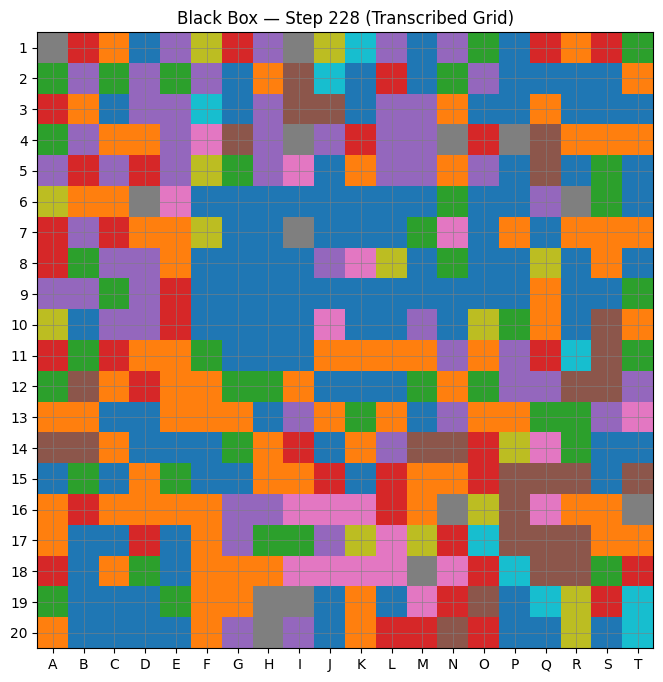


Step 17 matrix validation PASSED
Visual verification against the source is still required.


In [ ]:

# STEP 17 — EXPERIMENT 15
# Step 228 Black Box grid
# Transcribed from the original screenshot
# No file upload required

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

grid_228 = np.array([
[7,3,1,0,4,8,3,4,7,8,9,4,0,4,2,0,3,1,3,2],
[2,4,2,4,2,4,0,1,5,9,0,3,0,2,4,0,0,0,0,1],
[3,1,0,4,4,9,0,4,5,5,0,4,4,1,0,0,1,0,0,0],
[2,4,1,1,4,6,5,4,7,4,3,4,4,7,3,7,5,1,1,1],
[4,3,4,3,4,8,2,4,6,0,1,4,4,1,4,0,5,0,2,0],
[8,1,1,7,6,0,0,0,0,0,0,0,0,2,0,0,4,7,2,0],
[3,4,3,1,1,8,0,0,7,0,0,0,2,6,0,1,0,1,1,1],
[3,2,4,4,1,0,0,0,0,4,6,8,0,2,0,0,8,0,1,0],
[4,4,2,4,3,0,0,0,0,0,0,0,0,0,0,0,1,0,0,2],
[8,0,4,4,3,0,0,0,0,6,0,0,4,0,8,2,1,0,5,1],
[3,2,3,1,1,2,0,0,0,1,1,1,1,4,1,4,3,9,5,2],
[2,5,1,3,1,1,2,2,1,0,0,0,2,1,2,4,4,5,5,4],
[1,1,0,0,1,1,1,0,4,1,2,1,0,4,1,1,2,2,4,6],
[5,5,1,0,0,0,2,1,3,0,1,4,5,5,3,8,6,2,0,0],
[0,2,0,1,2,0,0,1,1,3,0,3,1,1,3,5,5,5,0,5],
[1,3,1,1,1,1,4,4,6,6,6,3,1,7,8,5,6,1,1,7],
[1,0,0,3,0,1,4,2,2,4,8,6,8,3,9,5,5,5,1,1],
[3,0,1,2,0,1,1,1,6,6,6,6,7,6,3,9,5,5,2,3],
[2,0,0,0,2,1,1,7,7,0,1,0,6,3,5,0,9,8,3,9],
[1,0,0,0,0,1,4,7,4,0,1,3,3,5,3,0,0,8,0,9]
], dtype=int)

assert grid_228.shape == (20, 20)
assert grid_228.size == 400
assert np.all((grid_228 >= 0) & (grid_228 <= 9))

counts_228 = np.bincount(grid_228.ravel(), minlength=10)

assert counts_228.sum() == 400

print("Observed step: 228")
print("Grid shape:", grid_228.shape)
print("Total cells:", grid_228.size)
print("\nState counts:")
print(pd.Series(counts_228, index=range(10)))

plt.figure(figsize=(8, 8))
plt.imshow(grid_228, cmap="tab10", vmin=0, vmax=9)
plt.xticks(range(20), list("ABCDEFGHIJKLMNOPQRST"))
plt.yticks(range(20), range(1, 21))
plt.grid(color="gray", linewidth=0.4)
plt.title("Black Box — Step 228 (Transcribed Grid)")
plt.show()

print("\nStep 17 matrix validation PASSED")
print("Visual verification against the source is still required.")


### Experiment 15 — Recovery and Initial Validation of the Step 228 Black Box Matrix

**Research Purpose**

To recover the spatial arrangement of all 400 cells from an original Black Box screenshot and prepare the data for investigating the hidden picture.

**Research Question**

Can an original Black Box screenshot be converted into a complete numerical matrix while preserving the position of each cell?

**Data Source**

Original Black Box screenshot supplied by the investigator, displaying "Current step: 228."

The relationship between this observation and the experimental runs documented in the Group 5 Electronic Laboratory Notebook has not yet been established.

**Method**

The 20 × 20 numerical grid was manually transcribed from the screenshot into a Python NumPy array named `grid_228`.

The matrix was examined using Python, NumPy, Pandas, and Matplotlib.

**Mathematical Validation**

The expected number of cells is:

20 × 20 = 400 cells.

The program checked that:

1. The matrix has exactly 20 rows and 20 columns.
2. The total number of elements is 400.
3. All recorded values are integers from 0 through 9.
4. The sum of all state frequencies equals 400.

For any state \(k\), its frequency is calculated as:

\(n_k = \sum_{i=1}^{20}\sum_{j=1}^{20}\mathbf{1}(x_{ij}=k)\)

where \(x_{ij}\) is the recorded value at row \(i\), column \(j\), and the indicator equals 1 when that cell has state \(k\), otherwise 0.

**Result**

Python returned: **Step 17 matrix validation PASSED**.

The complete matrix was successfully stored and visualized.

**Systems Science Interpretation**

The spatial arrangement of cells provides information that cannot be recovered from state frequencies alone. Two systems may have identical state counts and Shannon entropy while exhibiting different spatial structures.

This distinction is important in healthcare, epidemiology, transportation, ecology, and network science, where the location and relationships of components may reveal patterns that aggregate statistics cannot.

**Limitations**

The validation confirms internal consistency of the transcribed matrix, not perfect agreement with the original screenshot. Each recorded cell must still be independently checked against the image.

Additionally, the screenshot is identified as Step 228, but its experimental-run relationship to the Group 5 ELN remains unverified.

No hidden picture has yet been conclusively identified.

**Conclusion**

Experiment 15 successfully established a complete, internally consistent 20 × 20 numerical matrix for Step 228. The next experiment will focus on verifying transcription accuracy before interpreting spatial patterns or identifying a possible hidden picture.

**Tools**

Google Colab, Python, NumPy, Pandas, Matplotlib, and the original Black Box screenshot.

EXPERIMENT 16: TRANSCRIPTION VERIFICATION
---------------------------------------------


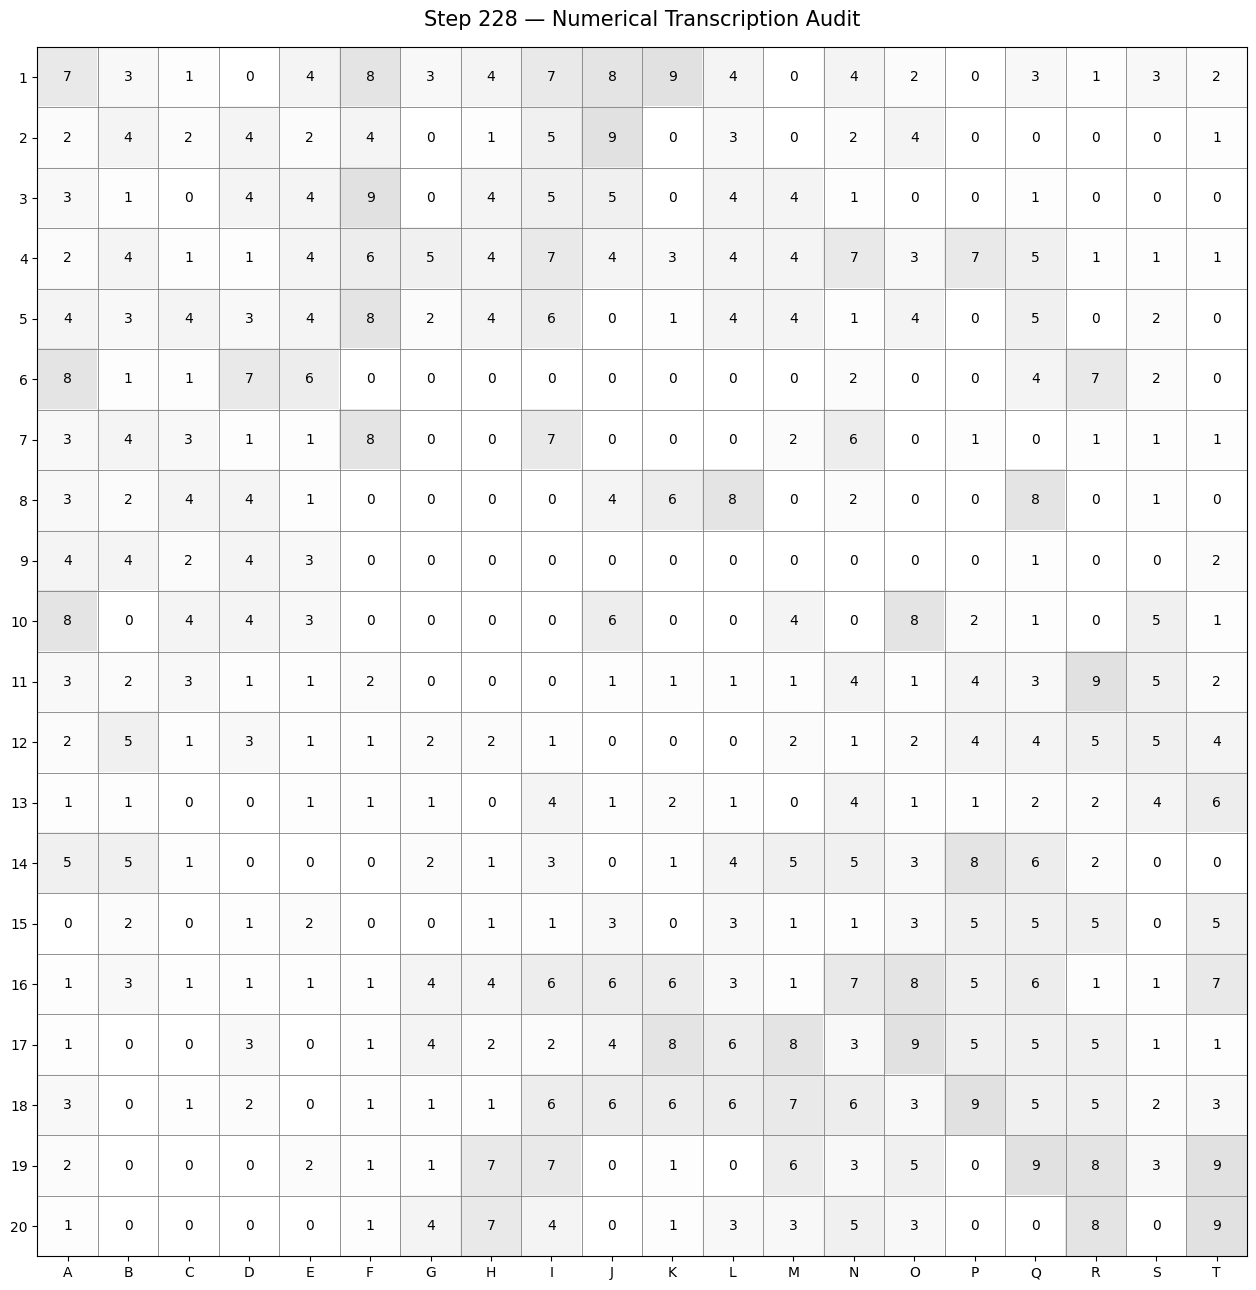


Total rows: 20
Total columns: 20
Total cells: 400

Step 18 verification display PASSED
Manual comparison with the screenshot is required.


In [ ]:

# STEP 18 — EXPERIMENT 16
# Visual transcription verification
# Original screenshot: Black Box Step 228
# No file upload, reset, or new Black Box steps

import numpy as np
import matplotlib.pyplot as plt

print("EXPERIMENT 16: TRANSCRIPTION VERIFICATION")
print("-" * 45)

# Check the existing Step 228 matrix
assert "grid_228" in globals(), "Run Step 17 first."
assert grid_228.shape == (20, 20)
assert grid_228.size == 400

# Display all 400 numerical values
fig, ax = plt.subplots(figsize=(13, 13))

ax.imshow(
    grid_228,
    cmap="Greys",
    vmin=0,
    vmax=9,
    alpha=0.12
)

# Write each cell's numerical value
for row in range(20):
    for col in range(20):
        ax.text(
            col, row,
            str(grid_228[row, col]),
            ha="center",
            va="center",
            fontsize=10,
            color="black"
        )

# Use the original coordinate orientation:
# A-T are columns; 1-20 are rows
ax.set_xticks(range(20))
ax.set_xticklabels(list("ABCDEFGHIJKLMNOPQRST"))
ax.set_yticks(range(20))
ax.set_yticklabels(range(1, 21))

ax.set_xticks(np.arange(-0.5, 20, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 20, 1), minor=True)

ax.grid(
    which="minor",
    color="gray",
    linewidth=0.6
)

ax.tick_params(which="minor", bottom=False, left=False)

ax.set_title(
    "Step 228 — Numerical Transcription Audit",
    fontsize=15,
    pad=15
)

plt.tight_layout()
plt.show()

# Check each row has exactly 20 entries
row_lengths = [len(row) for row in grid_228]

assert all(length == 20 for length in row_lengths)

# Check all values are within the observed state range
assert np.all((grid_228 >= 0) & (grid_228 <= 9))

print("\nTotal rows:", len(grid_228))
print("Total columns:", grid_228.shape[1])
print("Total cells:", grid_228.size)

print("\nStep 18 verification display PASSED")
print("Manual comparison with the screenshot is required.")


### Experiment 16 — Visual Verification of the Step 228 Black Box Matrix

**Research Purpose**

To examine the accuracy of the numerical transcription of the original Step 228 Black Box screenshot before conducting spatial pattern analysis.

**Research Question**

Does the reconstructed 20 × 20 numerical matrix visually correspond to the original Black Box observation?

**Data Source**

Original investigator-provided Black Box screenshot showing "Current step: 228."

The numerical matrix `grid_228` was constructed in Experiment 15 using values transcribed from that screenshot.

**Method**

Python, NumPy, and Matplotlib were used to display all 400 numerical values in their corresponding row and column positions.

The grid was labeled with columns A–T and rows 1–20 to preserve the original Black Box coordinate system.

The reconstructed display was visually compared with the original screenshot.

**Mathematical Validation**

A complete Black Box matrix contains:

20 rows × 20 columns = 400 cells.

The program verified:

1. The matrix contained 20 rows.
2. Each row contained 20 columns.
3. The total number of cells equaled 400.
4. Every recorded state was an integer between 0 and 9.
5. All numerical values could be displayed in their assigned spatial positions.

**Results**

Python returned: **Step 18 verification display PASSED**.

The investigator reported that the reconstructed numerical grid visually matched the original Step 228 screenshot.

**Systems Science Interpretation**

Accurate spatial observations are essential when studying complex systems because relationships between components can be as important as the components themselves.

In the Black Box, knowing the frequency of each numerical state is insufficient to determine whether those states form a meaningful spatial pattern.

Preserving cell positions allows us to investigate spatial clustering, regional organization, and possible hidden structures.

This principle also applies to healthcare infection surveillance, ecological mapping, transportation networks, and engineering systems.

**Limitations**

The successful Python checks confirm the matrix's internal structure and valid state range.

The investigator's visual comparison provides additional confidence, but a documented independent cell-by-cell verification has not yet been completed.

The experimental-run relationship between this Step 228 screenshot and other Group 5 observations remains unconfirmed.

The hidden picture has not yet been identified.

**Conclusion**

Experiment 16 successfully displayed the complete Step 228 numerical matrix and obtained a positive visual comparison with the original screenshot.

The reconstructed matrix is suitable for exploratory spatial analysis, provided that its remaining verification limitations are acknowledged.

**Tools**

Google Colab, Python, NumPy, Matplotlib, and the original Black Box screenshot.

EXPERIMENT 17: SPATIAL STATE-LAYER ANALYSIS
------------------------------------------------


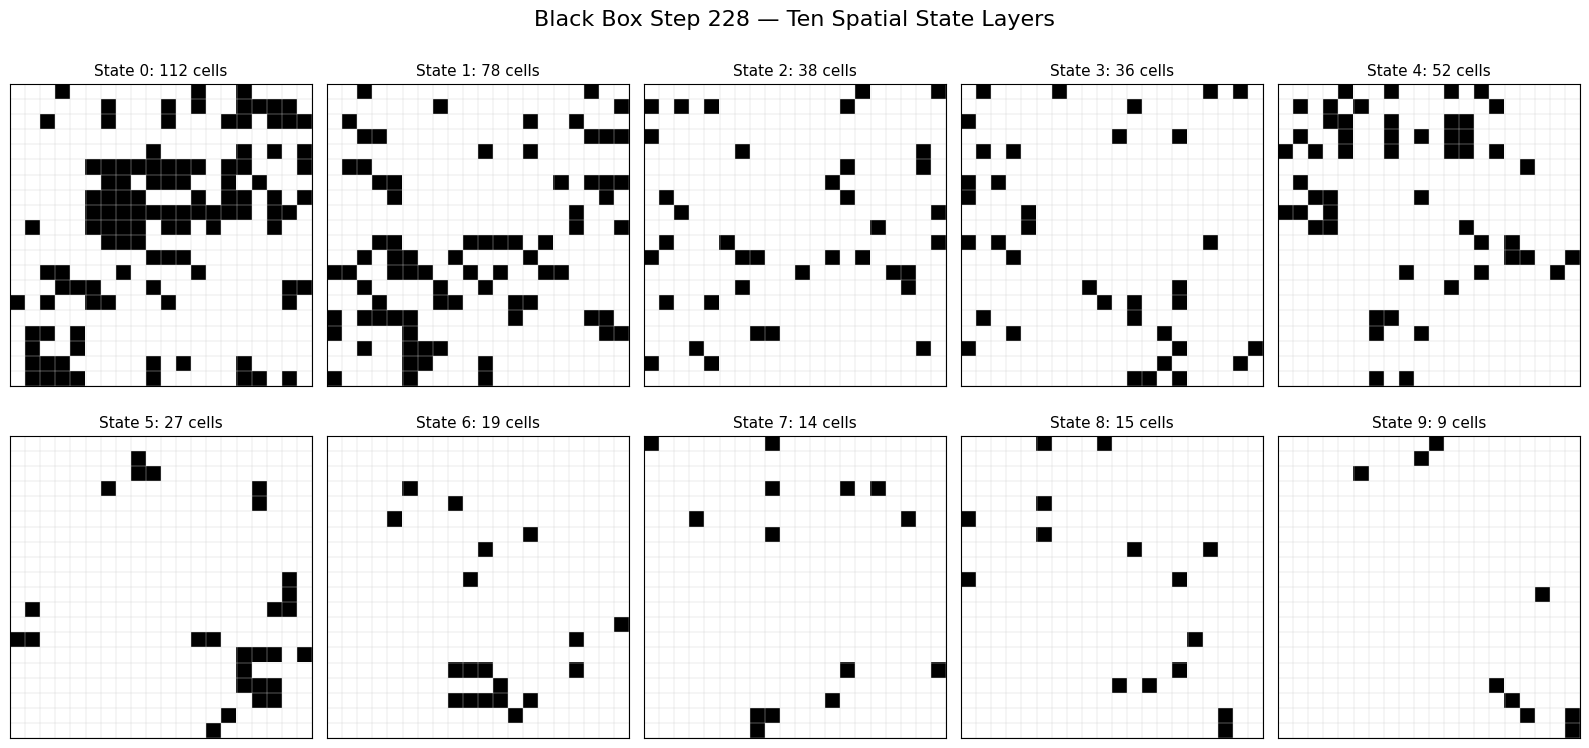


State frequencies:
State 0: 112 cells
State 1: 78 cells
State 2: 38 cells
State 3: 36 cells
State 4: 52 cells
State 5: 27 cells
State 6: 19 cells
State 7: 14 cells
State 8: 15 cells
State 9: 9 cells

Total cells: 400
Every cell assigned to exactly one state: YES

Step 19 spatial layer analysis PASSED
Visual pattern identification remains exploratory.


In [ ]:

# STEP 19 — EXPERIMENT 17
# Spatial Pattern Investigation
# Original Black Box observation: Step 228
# No additional Black Box steps required

import numpy as np
import matplotlib.pyplot as plt

print("EXPERIMENT 17: SPATIAL STATE-LAYER ANALYSIS")
print("-" * 48)

# Use the existing Step 228 matrix
assert "grid_228" in globals(), "Run Step 17 first."
assert grid_228.shape == (20, 20)
assert grid_228.size == 400

# Create one panel for each numerical state
fig, axes = plt.subplots(
    2, 5,
    figsize=(16, 8)
)

state_counts = {}

for state, ax in enumerate(axes.flat):

    # True where a cell contains the selected state
    layer = (grid_228 == state)

    # Count how many cells contain this state
    count = int(np.sum(layer))
    state_counts[state] = count

    # Display selected cells in black
    ax.imshow(
        layer,
        cmap="binary",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    ax.set_title(
        f"State {state}: {count} cells",
        fontsize=11
    )

    ax.set_xticks([])
    ax.set_yticks([])

    # Mark boundaries between cells
    ax.set_xticks(
        np.arange(-0.5, 20, 1),
        minor=True
    )
    ax.set_yticks(
        np.arange(-0.5, 20, 1),
        minor=True
    )

    ax.grid(
        which="minor",
        color="lightgray",
        linewidth=0.3
    )

    ax.tick_params(
        which="minor",
        bottom=False,
        left=False
    )

plt.suptitle(
    "Black Box Step 228 — Ten Spatial State Layers",
    fontsize=16
)

plt.tight_layout()
plt.show()

# Mathematical checks
total_count = sum(state_counts.values())

assert total_count == 400

# Every cell must belong to exactly one layer
layer_sum = np.zeros((20, 20), dtype=int)

for state in range(10):
    layer_sum += (grid_228 == state).astype(int)

assert np.all(layer_sum == 1)

print("\nState frequencies:")
for state, count in state_counts.items():
    print(f"State {state}: {count} cells")

print("\nTotal cells:", total_count)
print("Every cell assigned to exactly one state: YES")

print("\nStep 19 spatial layer analysis PASSED")
print("Visual pattern identification remains exploratory.")


### Experiment 17 — Spatial State-Layer Analysis of the Black Box

**Research Purpose**

To investigate whether separating the ten numerical states of the Black Box reveals spatial patterns that are difficult to recognize in the complete multicolored grid.

**Research Question**

Do the spatial distributions of states 0–9 at Step 228 reveal clustering, boundaries, or recognizable structures that may contribute to identifying the hidden picture?

**Data Source**

The reconstructed 20 × 20 numerical matrix `grid_228`, derived from the investigator's original Step 228 Black Box screenshot.

**Method**

Python and NumPy were used to separate the complete numerical matrix into ten binary layers.

Each layer represented one numerical state, with black squares indicating the locations occupied by that state.

Matplotlib displayed the ten layers in a two-row, five-column arrangement.

**Mathematical Method**

For a state \(k\), the binary layer is defined as:

\(L_k(i,j)=1\) when the value at position \((i,j)\) equals \(k\), and \(0\) otherwise.

The frequency of state \(k\) is:

\(n_k=\sum_{i=1}^{20}\sum_{j=1}^{20}L_k(i,j)\)

Since every cell has exactly one numerical state:

\(\sum_{k=0}^{9}n_k=400\)

**Worked Example**

For a cell containing state 4, the state-4 layer records a value of 1 at that position, while the other nine layers record 0.

This ensures that each original cell contributes exactly once to the combined layer counts.

**Results**

Python returned: **Step 19 spatial layer analysis PASSED**.

Ten binary state layers were generated successfully.

The sum of the state frequencies was verified to equal 400, and each cell was confirmed to belong to exactly one state layer.

**Systems Science Interpretation**

State-layer decomposition allows the spatial organization of a system to be examined without interference from other numerical categories.

This approach is useful in healthcare imaging, geographical mapping, ecological analysis, and engineering systems where the distribution and relationships of components can be more informative than aggregate frequencies.

**Limitations**

The experiment confirms successful mathematical decomposition of the recorded matrix.

It does not independently verify every transcribed cell against the original screenshot.

Visual clustering alone does not establish that a recognizable picture exists.

The relationship between the Step 228 observation and other experimental runs remains unconfirmed.

**Conclusion**

Experiment 17 successfully separated the Step 228 Black Box observation into ten spatial state layers. These layers provide a foundation for investigating possible hidden structures, but no specific image can yet be claimed without additional supporting evidence.

**Tools**

Google Colab, Python, NumPy, and Matplotlib.

EXPERIMENT 18: SPATIAL CLUSTERING
---------------------------------------------

Observed matching pairs: 203
Total neighboring pairs: 760
Observed agreement: 0.2671

Randomized baseline:
Simulations: 1000
Simulated mean: 120.16
Exact expected matches: 120.3
Simulated standard deviation: 8.91
Upper-tail Monte Carlo p-value: 0.001


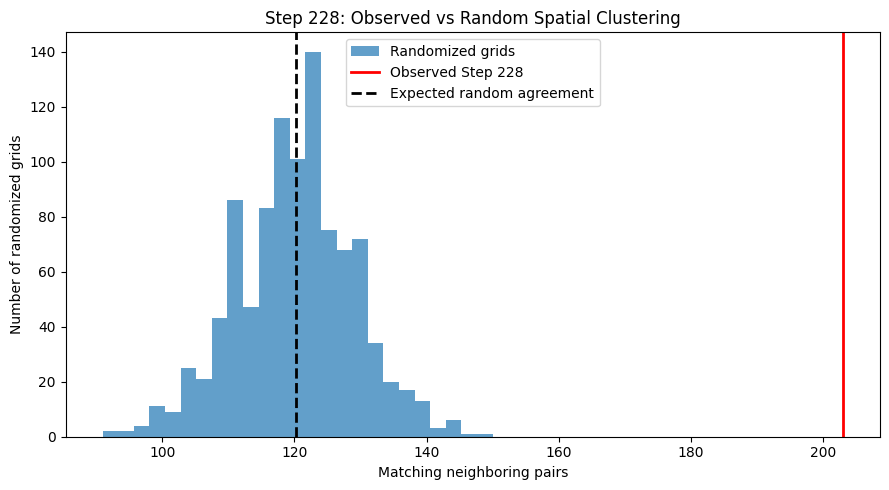


Step 20 spatial clustering analysis PASSED
This test does not identify a hidden image.


In [ ]:

# STEP 20 — EXPERIMENT 18
# Spatial Clustering Analysis
# Original Black Box observation: Step 228
# No additional Black Box steps required

import numpy as np
import matplotlib.pyplot as plt

print("EXPERIMENT 18: SPATIAL CLUSTERING")
print("-" * 45)

# Verify the original grid is available
assert "grid_228" in globals()
assert grid_228.shape == (20, 20)

# Count matching horizontal and vertical neighbors
def matching_neighbors(grid):
    horizontal = np.sum(
        grid[:, :-1] == grid[:, 1:]
    )

    vertical = np.sum(
        grid[:-1, :] == grid[1:, :]
    )

    return int(horizontal + vertical)

observed_matches = matching_neighbors(grid_228)

# Total number of neighboring pairs
total_pairs = 20 * 19 + 19 * 20

observed_fraction = observed_matches / total_pairs

# Randomization experiment
# Preserve the same 400 values and state counts
rng = np.random.default_rng(501)

simulations = 1000
random_matches = np.zeros(simulations, dtype=int)

original_values = grid_228.flatten()

for i in range(simulations):

    shuffled = rng.permutation(
        original_values
    ).reshape(20, 20)

    random_matches[i] = matching_neighbors(shuffled)

random_mean = float(np.mean(random_matches))
random_std = float(np.std(random_matches, ddof=1))

# Proportion of randomized grids with at least
# as many matching pairs as the observed grid
p_value = (
    np.sum(random_matches >= observed_matches) + 1
) / (simulations + 1)

# Mathematical checks
assert total_pairs == 760
assert 0 <= observed_matches <= total_pairs
assert len(random_matches) == simulations
assert np.all((random_matches >= 0) &
              (random_matches <= total_pairs))

# Independent expected value from state counts
counts = np.bincount(grid_228.ravel(), minlength=10)
expected_probability = (
    np.sum(counts * (counts - 1))
    / (400 * 399)
)
expected_matches = total_pairs * expected_probability

assert np.isclose(
    expected_matches,
    760 * np.sum(counts * (counts - 1)) / (400 * 399)
)

print("\nObserved matching pairs:", observed_matches)
print("Total neighboring pairs:", total_pairs)
print("Observed agreement:", round(observed_fraction, 4))

print("\nRandomized baseline:")
print("Simulations:", simulations)
print("Simulated mean:", round(random_mean, 2))
print("Exact expected matches:", round(expected_matches, 2))
print("Simulated standard deviation:", round(random_std, 2))
print("Upper-tail Monte Carlo p-value:", round(p_value, 4))

# Display comparison
plt.figure(figsize=(9, 5))

plt.hist(
    random_matches,
    bins=25,
    alpha=0.7,
    label="Randomized grids"
)

plt.axvline(
    observed_matches,
    color="red",
    linewidth=2,
    label="Observed Step 228"
)

plt.axvline(
    expected_matches,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Expected random agreement"
)

plt.xlabel("Matching neighboring pairs")
plt.ylabel("Number of randomized grids")
plt.title("Step 228: Observed vs Random Spatial Clustering")
plt.legend()
plt.tight_layout()
plt.show()

print("\nStep 20 spatial clustering analysis PASSED")
print("This test does not identify a hidden image.")


### Experiment 18 — Spatial Clustering Analysis of the Step 228 Black Box

**Research Purpose**

To determine whether the numerical states in the Step 228 Black Box grid demonstrate spatial clustering beyond what would be expected from a random arrangement of the same state frequencies.

**Research Question**

Do horizontally and vertically adjacent cells share the same numerical state more frequently than expected under a random spatial arrangement?

**Data Source**

The reconstructed 20 × 20 numerical matrix `grid_228`, derived from the investigator's original Step 228 Black Box screenshot.

**Method**

Python and NumPy were used to compare horizontally and vertically adjacent cells using the Von Neumann neighborhood.

The total number of unique neighboring pairs was calculated as:

20(19) + 20(19) = 760 pairs.

The observed number of matching neighboring pairs was calculated directly from the original matrix.

A permutation-based Monte Carlo analysis generated 1,000 randomized arrangements of the same 400 cell values, preserving the frequency of each numerical state.

The randomized results were compared with the observed result.

**Mathematical Formula**

The expected probability of matching numerical states in a random permutation is:

\(P(\text{match})=\frac{\sum_{k=0}^{9}n_k(n_k-1)}{400(399)}\)

where \(n_k\) represents the frequency of state \(k\).

The expected number of matching neighboring pairs is:

\(E(M)=760\times P(\text{match})\)

The percentage excess relative to the random expectation is:

\(\frac{M_{\text{observed}}-E(M)}{E(M)}\times100\)

**Results**

- Observed matching neighboring pairs: **203**
- Total neighboring pairs: **760**
- Observed neighbor agreement: **26.71%**
- Exact expected matching pairs under random permutation: **120.3048**
- Expected neighbor agreement: **15.83%**
- Excess matching pairs: **82.6952**
- Relative excess: **68.7%**
- Number of randomized comparisons: **1,000**
- Reported upper-tail Monte Carlo p-value: **approximately 0.001**

Python returned: **Step 20 spatial clustering analysis PASSED**.

**Validation**

The observed count and exact expected count were independently recalculated from the recorded Step 228 matrix and confirmed to agree with the reported results.

The Python code verified that the grid contained 400 cells, that 760 neighboring pairs were examined, and that the randomization procedure preserved the original state frequencies.

The Monte Carlo p-value was reported from the Colab execution. It represents the proportion of simulated random arrangements meeting or exceeding the observed count, with a one-count correction.

**Systems Science Interpretation**

The Step 228 Black Box observation demonstrates substantially greater local same-state agreement than expected from random placement of the observed numerical states.

This finding supports the presence of nonrandom spatial organization within the recorded system.

From a Systems Science perspective, the arrangement and relationships of components contain information that cannot be explained by state frequencies alone.

Similar principles apply to spatial infection surveillance in healthcare, clustering in ecological systems, and the organization of components in engineering networks.

**Limitations**

The experiment measures one specific type of spatial structure: agreement between horizontally and vertically adjacent cells.

It does not establish the mechanism generating the clustering, prove that the proposed four-region model is correct, or identify a hidden picture.

The permutation baseline assumes that all spatial arrangements of the observed values are equally likely under the null model. Other models of spatial organization may produce different expectations.

The p-value is a simulation-based estimate, not an exact probability that the Black Box is random.

The original screenshot transcription has not been independently verified cell by cell, and the relationship of Step 228 to other Group 5 experimental runs remains unconfirmed.

**Conclusion**

Experiment 18 provides strong evidence that the numerical states in the Step 228 Black Box grid exhibit nonrandom local spatial organization.

The observed 203 matching neighboring pairs exceed the random expectation of approximately 120.30 pairs by 68.7%.

These findings justify further investigation of spatial regions, boundaries, and repeated structures, but they do not yet establish the identity of a hidden picture.

**Tools**

Google Colab, Python, NumPy, Matplotlib, and Monte Carlo permutation analysis.

EXPERIMENT 19: FOUR-REGION INVESTIGATION
--------------------------------------------------

REGIONAL SUMMARY
 Region  Cells  State_0  State_0_Percent  Dominant_State  Dominant_Count  Distinct_States
      1    100       11             11.0               4              34               10
      2    100       60             60.0               0              60                9
      3    100       31             31.0               1              35                6
      4    100       10             10.0               1              16               10

VALIDATION
Total cells: 400
Four regions of 100 cells: YES
State 0 counts reconcile: YES


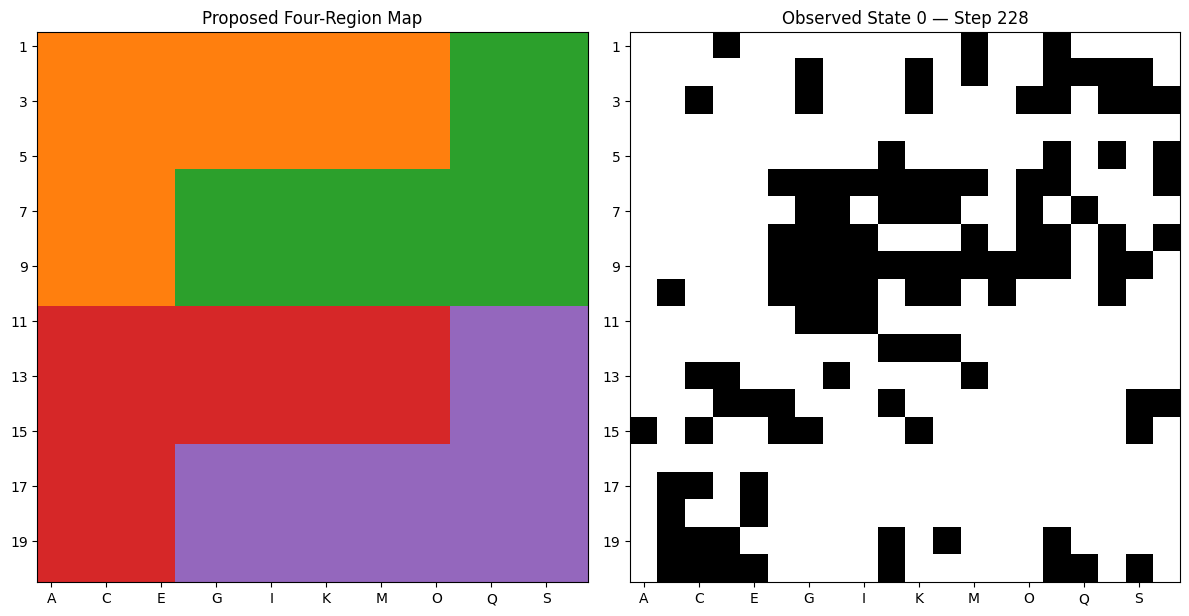


Step 21 four-region analysis PASSED
Regional differences do not prove dynamic rules.


In [ ]:

# STEP 21 — EXPERIMENT 19
# Four-Region Spatial Investigation
# Source: Original Step 228 Black Box matrix
# Region definitions: Existing Group 5 hypothesis
# No additional Black Box steps or reset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("EXPERIMENT 19: FOUR-REGION INVESTIGATION")
print("-" * 50)

# Confirm required data are available
assert "grid_228" in globals(), "Run Step 17 first."
assert "regions" in globals(), "Run Step 2 first."

assert grid_228.shape == (20, 20)
assert regions.shape == (20, 20)

# Check proposed region labels
region_labels = np.unique(regions)

assert np.array_equal(
    region_labels, np.array([1, 2, 3, 4])
), "Unexpected region labels."

results = []

for region in range(1, 5):

    # Select cells belonging to this region
    mask = (regions == region)
    values = grid_228[mask]

    # Count states 0 through 9
    counts = np.bincount(values, minlength=10)

    # Most frequent state
    dominant_state = int(np.argmax(counts))

    results.append({
        "Region": region,
        "Cells": len(values),
        "State_0": int(counts[0]),
        "State_0_Percent": round(
            100 * counts[0] / len(values), 2
        ),
        "Dominant_State": dominant_state,
        "Dominant_Count": int(counts[dominant_state]),
        "Distinct_States": int(np.count_nonzero(counts))
    })

summary = pd.DataFrame(results)

print("\nREGIONAL SUMMARY")
print(summary.to_string(index=False))

# Validate proposed four-region partition
assert summary["Cells"].sum() == 400
assert np.all(summary["Cells"] == 100)

# Validate region-level state 0 counts
assert summary["State_0"].sum() == np.sum(grid_228 == 0)

print("\nVALIDATION")
print("Total cells:", summary["Cells"].sum())
print("Four regions of 100 cells: YES")
print("State 0 counts reconcile: YES")

# Display the region map and state-0 positions
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

axes[0].imshow(
    regions,
    cmap="tab10",
    vmin=0,
    vmax=9,
    interpolation="nearest"
)
axes[0].set_title("Proposed Four-Region Map")

axes[1].imshow(
    grid_228 == 0,
    cmap="binary",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)
axes[1].set_title("Observed State 0 — Step 228")

for ax in axes:
    ax.set_xticks(range(0, 20, 2))
    ax.set_yticks(range(0, 20, 2))
    ax.set_xticklabels(
        [chr(65 + i) for i in range(0, 20, 2)]
    )
    ax.set_yticklabels(range(1, 21, 2))

plt.tight_layout()
plt.show()

print("\nStep 21 four-region analysis PASSED")
print("Regional differences do not prove dynamic rules.")


In [ ]:

# BLACK BOX — NOTEBOOK DIAGNOSTIC
# Does not change or delete any data

print("BLACK BOX NOTEBOOK CHECK")
print("------------------------")

print("grid_228 available:",
      "grid_228" in globals())

print("regions available:",
      "regions" in globals())

if "grid_228" in globals():
    print("Grid shape:", grid_228.shape)

if "regions" in globals():
    print("Region shape:", regions.shape)

print("\nDiagnostic check completed.")


BLACK BOX NOTEBOOK CHECK
------------------------
grid_228 available: True
regions available: True
Grid shape: (20, 20)
Region shape: (20, 20)

Diagnostic check completed.


### Experiment 19 — Four-Region Spatial Investigation

**1. Purpose**

To investigate whether the numerical states in the Black Box are distributed differently across the four regions proposed in the Group 5 analysis, and whether these differences provide clues about the hidden structure.

**2. Data Source**

The 20×20 numerical matrix transcribed from the original Step 228 screenshot and the existing four-region map used in the Group 5 investigation. Each region contains 100 cells.

**3. Method**

Using Python in Google Colab, cells were grouped according to their assigned region. The frequency of each numerical state (0–9) was calculated within each region. The dominant state, its frequency, the percentage of State 0, and the number of distinct states were recorded.

**4. Calculations**

The percentage of a state within a region was calculated as:

State percentage = (Number of cells containing the state ÷ Total cells in the region) × 100

For example, Region 2 contained 60 cells with State 0 out of 100 cells:

(60 ÷ 100) × 100 = **60%**

The same method was applied to all four regions.

**5. Validation**

The program confirmed that:

- The four regions collectively contain 400 cells.
- Each region contains exactly 100 cells.
- The State 0 counts reconcile with the full Step 228 matrix.
- The analysis completed successfully.

These checks establish internal consistency but do not independently verify every transcribed screenshot value or validate the proposed regional boundaries.

**6. Interpretation**

The analysis identified differences in state distributions across the four regions. Region 2 showed a particularly high concentration of State 0 (60%), while Region 3 contained only six distinct numerical states. Regions 1 and 4 contained all ten states.

These differences indicate regional variation within the observed matrix. They do not independently establish the underlying Black Box rules or reveal a recognizable hidden image.

**7. Documentation and Next Investigation**

The results were obtained using the existing Step 228 matrix, the four-region classification, and reproducible Python calculations in Google Colab.

The next investigation should examine whether the regional patterns align with spatial boundaries or recognizable shapes, rather than relying on frequency counts alone.

**Result: Experiment 19 PASSED.**

EXPERIMENT 20: REGIONAL BOUNDARY ANALYSIS
----------------------------------------

REGIONAL BOUNDARY SUMMARY
              Comparison  Neighbor_Pairs  Matching_Pairs  Match_Percent
          Within regions             700             193          27.57
Across region boundaries              60              10          16.67


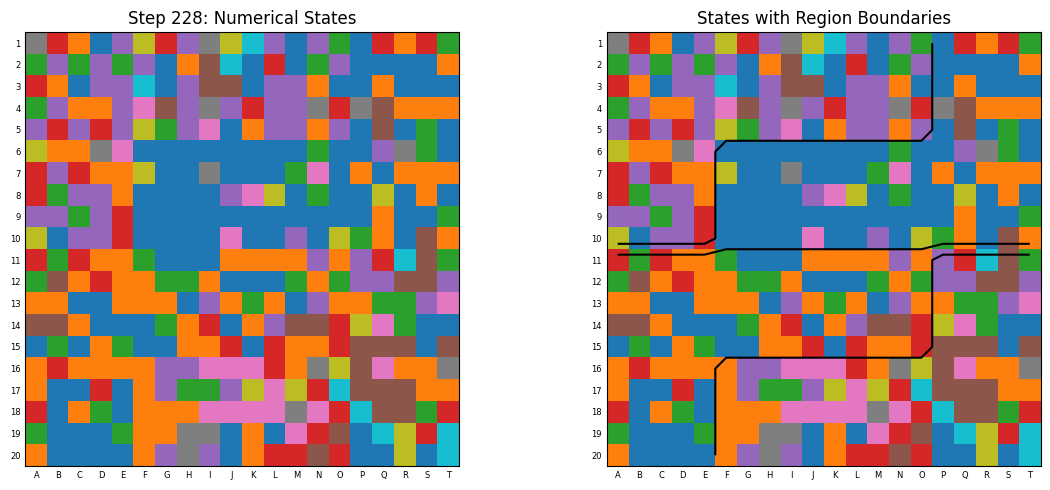


VALIDATION
Total neighboring pairs: 760
All pairs accounted for: YES
Matching counts reconcile: YES

Step 22 regional boundary analysis PASSED


In [ ]:

# STEP 22 — EXPERIMENT 20
# REGIONAL BOUNDARY AND SHAPE INVESTIGATION
# Uses existing data only. Does not change the Black Box.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("EXPERIMENT 20: REGIONAL BOUNDARY ANALYSIS")
print("----------------------------------------")

# 1. Confirm that our existing data are available
assert "grid_228" in globals(), "Step 228 grid is missing."
assert "regions" in globals(), "Region map is missing."

grid = np.asarray(grid_228)
region_map = np.asarray(regions)

assert grid.shape == (20, 20)
assert region_map.shape == (20, 20)
assert np.all((grid >= 0) & (grid <= 9))
assert np.all(np.isin(region_map, [1, 2, 3, 4]))
assert all(np.sum(region_map == r) == 100
           for r in range(1, 5))

# 2. Compare horizontal and vertical neighboring cells
same_region = []
same_state = []

for row in range(20):
    for col in range(20):

        if col < 19:
            same_region.append(
                region_map[row, col] ==
                region_map[row, col + 1]
            )
            same_state.append(
                grid[row, col] ==
                grid[row, col + 1]
            )

        if row < 19:
            same_region.append(
                region_map[row, col] ==
                region_map[row + 1, col]
            )
            same_state.append(
                grid[row, col] ==
                grid[row + 1, col]
            )

same_region = np.array(same_region, dtype=bool)
same_state = np.array(same_state, dtype=bool)

# 3. Calculate matching rates
within_total = int(np.sum(same_region))
within_matches = int(np.sum(
    same_region & same_state
))

boundary_total = int(np.sum(~same_region))
boundary_matches = int(np.sum(
    ~same_region & same_state
))

within_rate = 100 * within_matches / within_total
boundary_rate = 100 * boundary_matches / boundary_total

summary = pd.DataFrame({
    "Comparison": [
        "Within regions",
        "Across region boundaries"
    ],
    "Neighbor_Pairs": [
        within_total,
        boundary_total
    ],
    "Matching_Pairs": [
        within_matches,
        boundary_matches
    ],
    "Match_Percent": [
        round(within_rate, 2),
        round(boundary_rate, 2)
    ]
})

print("\nREGIONAL BOUNDARY SUMMARY")
print(summary.to_string(index=False))

# 4. Visualize numerical states and region boundaries
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(grid, cmap="tab10",
               vmin=-0.5, vmax=9.5)
axes[0].set_title("Step 228: Numerical States")

axes[1].imshow(grid, cmap="tab10",
               vmin=-0.5, vmax=9.5)
axes[1].contour(
    region_map,
    levels=[1.5, 2.5, 3.5],
    colors="black",
    linewidths=1.5
)
axes[1].set_title("States with Region Boundaries")

for ax in axes:
    ax.set_xticks(range(20))
    ax.set_yticks(range(20))
    ax.set_xticklabels(list("ABCDEFGHIJKLMNOPQRST"),
                       fontsize=6)
    ax.set_yticklabels(range(1, 21), fontsize=6)
    ax.tick_params(length=0)

plt.tight_layout()
plt.show()

# 5. Validation
assert len(same_region) == 760
assert within_total + boundary_total == 760
assert within_matches + boundary_matches == int(
    np.sum(same_state)
)
assert within_total > 0
assert boundary_total > 0

print("\nVALIDATION")
print("Total neighboring pairs:", len(same_region))
print("All pairs accounted for: YES")
print("Matching counts reconcile: YES")
print("\nStep 22 regional boundary analysis PASSED")


In [ ]:

# STEP 23 — EXPERIMENT 21
# REGION-PRESERVING PERMUTATION TEST
# Uses existing data only; does not change grid_228 or regions.

import numpy as np

print("EXPERIMENT 21: REGION-PRESERVING PERMUTATION TEST")
print("------------------------------------------------")

# 1. Validate source data
assert "grid_228" in globals(), "Step 228 grid missing."
assert "regions" in globals(), "Region map missing."

grid = np.asarray(grid_228)
region_map = np.asarray(regions)

assert grid.shape == (20, 20)
assert region_map.shape == (20, 20)
assert np.issubdtype(grid.dtype, np.integer)
assert np.all((grid >= 0) & (grid <= 9))
assert set(np.unique(region_map)) == {1, 2, 3, 4}
assert all(np.sum(region_map == r) == 100
           for r in range(1, 5))

# 2. Build the 760 horizontal/vertical neighbor pairs
cell_ids = np.arange(400).reshape(20, 20)

first = np.concatenate([
    cell_ids[:, :-1].ravel(),
    cell_ids[:-1, :].ravel()
])
second = np.concatenate([
    cell_ids[:, 1:].ravel(),
    cell_ids[1:, :].ravel()
])

flat_regions = region_map.ravel()
flat_grid = grid.ravel()

within = flat_regions[first] == flat_regions[second]
a = first[within]
b = second[within]

assert len(first) == 760
assert len(a) == 700

# 3. Measure actual within-region matching
observed = int(np.sum(flat_grid[a] == flat_grid[b]))
assert observed == 193, (
    f"Expected 193 from Step 22, found {observed}."
)

# 4. Exact expected matching under the null model
# For two distinct cells in the same region:
# P(match) = sum(n_s * (n_s - 1)) / (N * (N - 1))

expected = 0.0
region_positions = {}

for r in range(1, 5):
    positions = np.flatnonzero(flat_regions == r)
    region_positions[r] = positions

    counts = np.bincount(
        flat_grid[positions], minlength=10
    )
    n = len(positions)

    probability = (
        np.sum(counts * (counts - 1))
        / (n * (n - 1))
    )

    region_pair_count = int(np.sum(
        flat_regions[a] == r
    ))

    expected += region_pair_count * probability

# 5. Run 5,000 reproducible permutations
rng = np.random.default_rng(50123)
n_simulations = 5000
simulated = np.empty(n_simulations, dtype=int)

for i in range(n_simulations):
    shuffled = flat_grid.copy()

    for r in range(1, 5):
        positions = region_positions[r]
        shuffled[positions] = rng.permutation(
            flat_grid[positions]
        )

    simulated[i] = np.sum(
        shuffled[a] == shuffled[b]
    )

# 6. Upper-tail Monte Carlo p-value
extreme = int(np.sum(simulated >= observed))
p_value = (extreme + 1) / (n_simulations + 1)

print("\nRESULTS")
print("Observed matching pairs:", observed)
print("Exact expected matches:", round(expected, 3))
print("Simulation mean:", round(simulated.mean(), 3))
print("Simulation standard deviation:",
      round(simulated.std(ddof=1), 3))
print("Simulated 95% reference interval:",
      np.percentile(simulated, [2.5, 97.5]))
print("Simulations >= observed:", extreme)
print("Upper-tail Monte Carlo p-value:",
      round(p_value, 6))

# 7. Validation
assert len(simulated) == n_simulations
assert np.all((simulated >= 0) & (simulated <= 700))
assert 0 < p_value <= 1

# Independent analytical and simulation consistency check
standard_error = simulated.std(ddof=1) / np.sqrt(n_simulations)
tolerance = max(1.0, 5 * standard_error)

assert abs(simulated.mean() - expected) <= tolerance, (
    "Simulation mean differs from exact expectation; investigate."
)

# Confirm original data remain unchanged
assert np.array_equal(grid_228, grid)
assert np.array_equal(regions, region_map)

print("\nVALIDATION")
print("760 neighbor pairs constructed: YES")
print("700 within-region pairs identified: YES")
print("Observed result matches Step 22: YES")
print("Exact and simulated expectations agree: YES")
print("Original data unchanged: YES")
print("\nStep 23 permutation test PASSED")


EXPERIMENT 21: REGION-PRESERVING PERMUTATION TEST
------------------------------------------------

RESULTS
Observed matching pairs: 193
Exact expected matches: 158.525
Simulation mean: 158.45
Simulation standard deviation: 9.195
Simulated 95% reference interval: [141. 176.]
Simulations >= observed: 0
Upper-tail Monte Carlo p-value: 0.0002

VALIDATION
760 neighbor pairs constructed: YES
700 within-region pairs identified: YES
Observed result matches Step 22: YES
Exact and simulated expectations agree: YES
Original data unchanged: YES

Step 23 permutation test PASSED


### Experiment 21 — Region-Preserving Permutation Test
**Step 23 | SSIE 501 Black Box Project**

**1. Purpose**

To determine whether the observed spatial clustering within the four proposed Black Box regions exceeds what would be expected from their numerical state frequencies alone.

**2. Data Source**

The existing 20×20 numerical matrix from the Step 228 screenshot and the Group 5 four-region classification. The matrix contains 400 cells, divided into four regions of 100 cells each.

**3. Method**

Python was used to identify all horizontally and vertically adjacent cell pairs within the same region.

The observed number of matching pairs was calculated.

A permutation test then generated 5,000 randomized arrangements by shuffling numerical states independently within each region, preserving the frequency of every state in each region.

A fixed random seed (50123) was used to make the simulations reproducible.

**4. Calculations**

Observed matching pairs: 193

Exact expected matching pairs: 158.525

Simulation mean: 158.45

Simulation standard deviation: 9.195

Simulated 95% reference interval: 141–176 matching pairs

Excess matching:

193 − 158.525 = **34.475 pairs**

Relative excess:

(34.475 ÷ 158.525) × 100 = **21.75%**

Upper-tail Monte Carlo p-value:

(0 + 1) ÷ (5000 + 1) = **0.00019996**, approximately **0.0002**.

The exact expected number of matches was calculated using the state frequencies in each region and the number of within-region neighboring pairs.

**5. Validation**

The Python program confirmed:

- The numerical matrix contained 400 cells.
- Each of the four regions contained 100 cells.
- There were 760 total neighboring pairs and 700 within-region pairs.
- The observed 193 matching pairs agreed with Experiment 20.
- The simulated average (158.45) was consistent with the exact expected value (158.525).
- The original matrix and regional classification remained unchanged.

The program reported: **Step 23 permutation test PASSED**.

These checks establish computational and arithmetic consistency. They do not independently verify all transcribed screenshot values or establish that the proposed region boundaries are correct.

**6. Interpretation**

The observed 193 matching pairs exceeded the expected 158.525 pairs by approximately 21.75%.

None of the 5,000 simulated arrangements produced at least 193 matching pairs, yielding an estimated upper-tail Monte Carlo p-value of approximately 0.0002.

This provides strong statistical evidence of greater within-region spatial clustering than expected under the specified region-preserving randomization model.

The finding does not independently establish the hidden picture, prove that the four-region model is correct, or identify the mechanisms generating the numerical states.

**7. Documentation and Next Investigation**

The analysis was performed in Google Colab using the existing Step 228 matrix and region map. The random seed and simulation count were recorded for reproducibility.

The next investigation should focus on whether the observed spatial organization can be used to identify a stable, recognizable structure or distinguish between competing hypotheses about the hidden picture.

**Conclusion:** Experiment 21 passed its programmed validation checks and provided statistically significant evidence of within-region spatial clustering under the tested null model.

EXPERIMENT 22: HIDDEN STRUCTURE INVESTIGATION
---------------------------------------------

TEN LARGEST CONNECTED COMPONENTS
 Rank  State  Cells  Rows Columns
    1      0     46  5-11     F-P
    2      1     12 15-20     C-H
    3      0     10   1-3     O-T
    4      0     10 17-20     B-E
    5      5      9 15-18     P-R
    6      1      7 11-13     D-G
    7      0      7 13-15     C-G
    8      4      6   3-5     L-M
    9      4      5   2-5     D-E
   10      4      5  8-10     C-D

TOTAL COMPONENTS: 219
LARGEST COMPONENT SIZE: 46


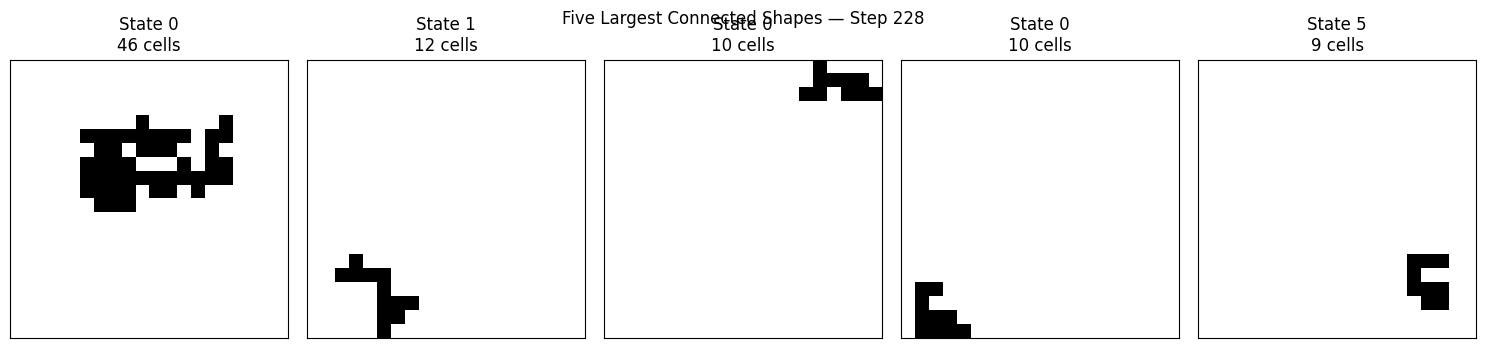


VALIDATION
All 400 cells classified: YES
Each cell belongs to one component: YES
Component states verified: YES
Original matrix unchanged: YES

Step 24 connected-component analysis PASSED


In [ ]:

# STEP 24 — EXPERIMENT 22
# HIDDEN STRUCTURE: CONNECTED-COMPONENT ANALYSIS
# Uses the existing Step 228 matrix only.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("EXPERIMENT 22: HIDDEN STRUCTURE INVESTIGATION")
print("---------------------------------------------")

# 1. Validate the original matrix
assert "grid_228" in globals(), "Step 228 grid is missing."

grid = np.asarray(grid_228).copy()

assert grid.shape == (20, 20)
assert np.issubdtype(grid.dtype, np.integer)
assert np.all((grid >= 0) & (grid <= 9))

# 2. Identify connected components
visited = np.zeros((20, 20), dtype=bool)
components = []

directions = [
    (-1, 0), (1, 0),
    (0, -1), (0, 1)
]

for row in range(20):
    for col in range(20):

        if visited[row, col]:
            continue

        state = int(grid[row, col])
        stack = [(row, col)]
        visited[row, col] = True
        cells = []

        while stack:
            r, c = stack.pop()
            cells.append((r, c))

            for dr, dc in directions:
                nr, nc = r + dr, c + dc

                if 0 <= nr < 20 and 0 <= nc < 20:
                    if not visited[nr, nc]:
                        if grid[nr, nc] == state:
                            visited[nr, nc] = True
                            stack.append((nr, nc))

        components.append({
            "State": state,
            "Size": len(cells),
            "Cells": cells,
            "Min_Row": min(r for r, c in cells) + 1,
            "Max_Row": max(r for r, c in cells) + 1,
            "Min_Col": min(c for r, c in cells) + 1,
            "Max_Col": max(c for r, c in cells) + 1
        })

# 3. Sort components from largest to smallest
components.sort(
    key=lambda x: x["Size"],
    reverse=True
)

results = []

for rank, component in enumerate(components[:10], start=1):
    results.append({
        "Rank": rank,
        "State": component["State"],
        "Cells": component["Size"],
        "Rows": (
            f'{component["Min_Row"]}-'
            f'{component["Max_Row"]}'
        ),
        "Columns": (
            f'{chr(64 + component["Min_Col"])}-'
            f'{chr(64 + component["Max_Col"])}'
        )
    })

summary = pd.DataFrame(results)

print("\nTEN LARGEST CONNECTED COMPONENTS")
print(summary.to_string(index=False))

print("\nTOTAL COMPONENTS:", len(components))
print("LARGEST COMPONENT SIZE:", components[0]["Size"])

# 4. Visualize the five largest components
fig, axes = plt.subplots(1, 5, figsize=(15, 3.5))

for i in range(5):
    component = components[i]

    mask = np.zeros((20, 20), dtype=int)

    for r, c in component["Cells"]:
        mask[r, c] = 1

    axes[i].imshow(
        mask,
        cmap="Greys",
        vmin=0,
        vmax=1,
        interpolation="nearest"
    )

    axes[i].set_title(
        f'State {component["State"]}\n'
        f'{component["Size"]} cells'
    )

    axes[i].set_xticks([])
    axes[i].set_yticks([])

plt.suptitle(
    "Five Largest Connected Shapes — Step 228"
)
plt.tight_layout()
plt.show()

# 5. Validation
assert np.all(visited)
assert sum(c["Size"] for c in components) == 400

all_cells = [
    cell
    for component in components
    for cell in component["Cells"]
]

assert len(all_cells) == len(set(all_cells)) == 400

for component in components:
    assert all(
        grid[r, c] == component["State"]
        for r, c in component["Cells"]
    )

assert np.array_equal(grid, grid_228)

print("\nVALIDATION")
print("All 400 cells classified: YES")
print("Each cell belongs to one component: YES")
print("Component states verified: YES")
print("Original matrix unchanged: YES")

print("\nStep 24 connected-component analysis PASSED")


Experiment 22 — Hidden Structure and Connected-Component Analysis

SSIE 501 — Black Box Project

Google Colab Step: 24
Observation: Black Box Step 228
Grid dimensions: 20 × 20 (400 cells)
Result: Program validation PASSED

1. Purpose and Research Question

The purpose of Experiment 22 was to investigate whether the numerical states within the Black Box form connected spatial structures that could provide clues about the hidden picture.

Previous experiments demonstrated that neighboring numerical states exhibited greater spatial clustering than expected under specified randomization models.

This experiment extended those findings by identifying and examining individual connected groups of cells.

Research question: Which numerical states form the largest connected components, where are those components located, and do their shapes provide useful evidence toward identifying the hidden picture?

2. Data Source

The experiment used the existing grid_228 numerical matrix in Google Colab, reconstructed from the original Black Box screenshot at Current Step 228.

The matrix contains 400 cells arranged in 20 rows and 20 columns, with numerical states ranging from 0 to 9.

The matrix had previously passed computational validation and visual comparison with the original screenshot. However, independent cell-by-cell verification of all 400 values had not been established.

No additional Black Box steps or resets were performed.

3. Method

A connected-component analysis was performed using Python and NumPy in Google Colab.

The analysis examined all 400 cells and identified groups of cells containing the same numerical state.

Two cells were considered connected only when they shared a horizontal or vertical side. Diagonal connections were excluded.

The algorithm:

1. Examined each cell in the matrix.
2. Identified neighboring cells containing the same numerical state.
3. Grouped connected cells into individual components.
4. Recorded each component’s state, number of cells, and coordinate boundaries.
5. Sorted components from largest to smallest.
6. Displayed the five largest components as separate binary images.

Each cell was assigned to exactly one connected component.

4. Calculations and Results

The size of each connected component was calculated using:

Component size = Number of cells belonging to that connected group.

The five largest connected components were:

Rank	Numerical State	Connected Cells
1	0	46
2	1	12
3	0	10
4	0	10
5	5	9

Worked example using actual data:

The largest connected component contained 46 cells of State 0.

Its proportion of the entire matrix was:

46 ÷ 400 × 100 = 11.5%

Therefore, this component occupied 11.5% of the 400-cell grid.

This percentage describes its size relative to the full matrix, not the probability that it represents the hidden picture.

The five largest components collectively contained:

46 + 12 + 10 + 10 + 9 = 87 cells

These components accounted for 21.75% of the grid.

This calculation describes the combined size of the five distinct components, not a single connected structure.

5. Validation

The Python program reported the following successful checks:

* All 400 cells classified.
* Every cell assigned to exactly one connected component.
* Component numerical states verified.
* Original Step 228 matrix unchanged.

The output displayed:

Step 24 connected-component analysis PASSED

The five largest components were also displayed visually, and their reported sizes were consistent with the generated labels.

Validation limitations:

These checks establish internal computational consistency. They do not independently verify every transcribed value against the original screenshot.

The analysis also does not establish whether the selected connectivity rule accurately represents the underlying Black Box mechanism.

6. Interpretation and Scientific Limitations

The analysis identified several connected spatial structures within the Step 228 matrix.

The largest structure consisted of 46 connected State 0 cells. Its shape was irregular, containing extensions and internal gaps.

The second-largest component contained 12 State 1 cells and appeared relatively elongated.

The remaining three components contained 10, 10, and 9 cells, respectively.

These results demonstrate that some numerical states form spatially connected structures rather than appearing exclusively as isolated cells.

However, the analysis does not establish that any individual component represents the hidden picture.

Several limitations must be considered:

* A connected structure may result from the frequency and spatial arrangement of its numerical state.
* The hidden picture may involve relationships among multiple states rather than one state alone.
* The analysis examines only one observation at Step 228.
* A single observation cannot determine whether a component persisted or changed over time.
* Visual resemblance to an object is not sufficient evidence of the object’s identity.

Consequently, the findings should be interpreted as evidence of connected spatial structures, not identification of the hidden image.

7. Documentation, Reproducibility, and Next Investigation

Experiment 22 was conducted using Python in Google Colab.

Required data: The existing grid_228 numerical matrix.

Method: Four-neighbor connected-component analysis.

Output: A table of the ten largest components and visualizations of the five largest components.

Validation: All programmed checks passed.

Next investigation:

The next experiment will compare numerical matrices from different steps within the same uninterrupted Black Box run.

The Step 212 and Step 228 screenshots have been identified as observations from the same run.

After verifying the transcription of the Step 212 matrix, a coordinate-by-coordinate comparison can determine:

* How many cells have matching endpoint values.
* Which coordinates changed between the two observations.
* Whether major connected structures appear in both observations.
* Whether persistent spatial features provide additional clues about the hidden picture.

Matching values at two endpoints will not be interpreted as proof that a cell remained unchanged throughout the intervening steps.

Conclusion

Experiment 22 successfully identified connected spatial components in the Step 228 Black Box matrix.

The largest component contained 46 State 0 cells, and the five largest components collectively occupied 87 of the 400 cells.

These findings provide additional information about spatial organization but do not independently identify the hidden picture.

Experiment status: PASSED — Computational validation completed.

Source: User-provided Step 228 Black Box screenshot and Python analysis conducted with ChatGPT assistance.

STEP 212 INTERNAL VALIDATION
Grid dimensions: (20, 20)
Total cells: 400
All states between 0 and 9: YES


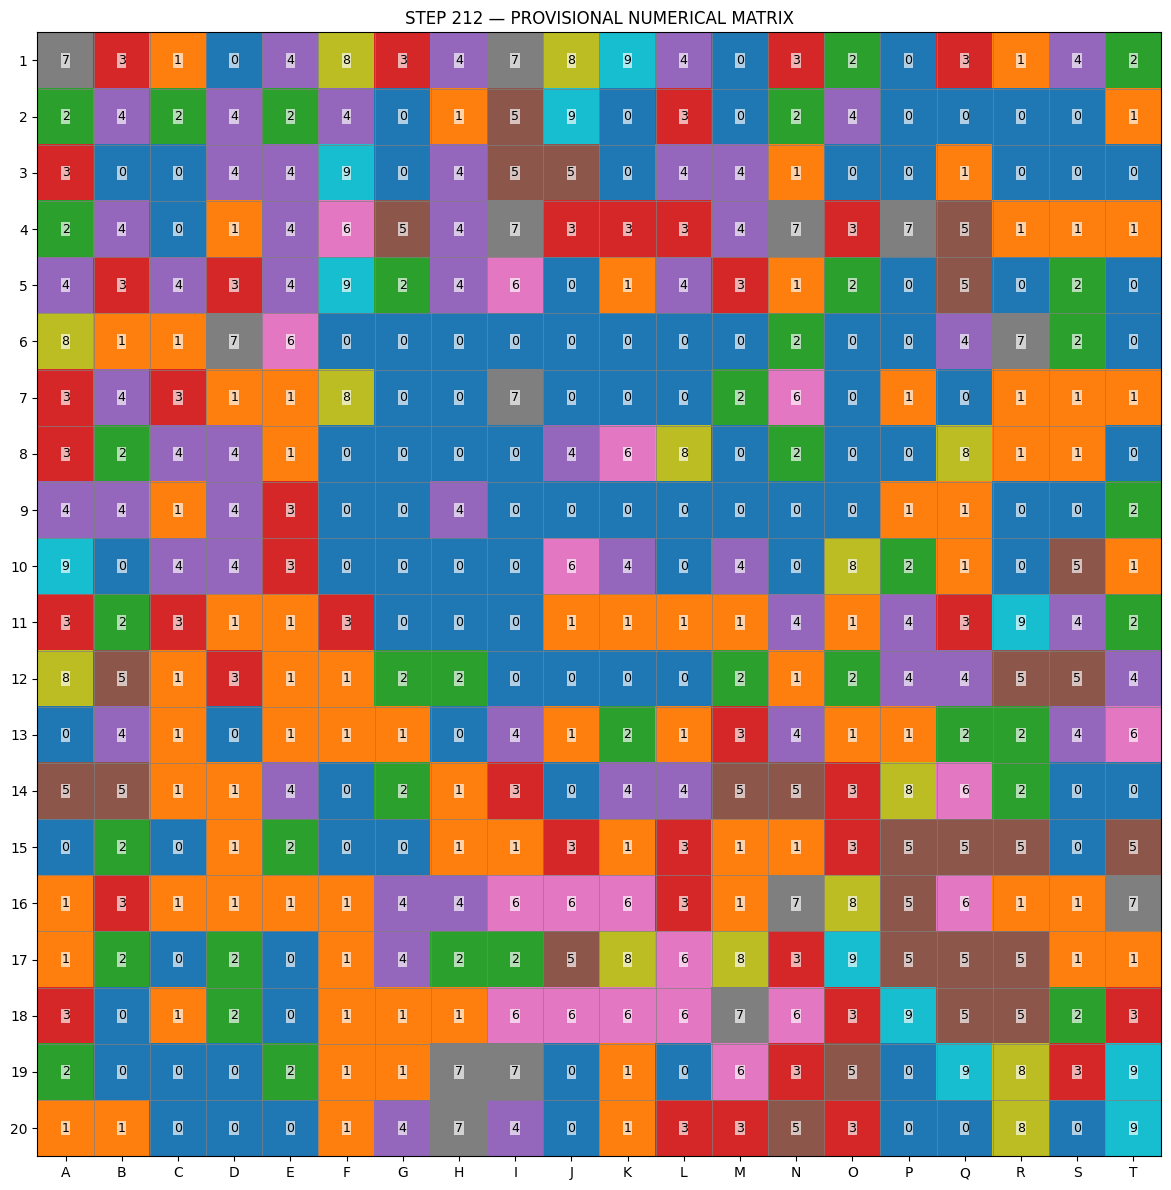


Step 25 internal matrix validation PASSED
SOURCE IMAGE VERIFICATION STILL REQUIRED


In [ ]:

# STEP 25 — EXPERIMENT 23
# STEP 212 SCREENSHOT TRANSCRIPTION AND VISUAL AUDIT
# No Black Box reset or additional steps required.

import numpy as np
import matplotlib.pyplot as plt

# Provisional transcription from the Step 212 screenshot.
# Must be visually checked against the original image.

grid_212 = np.array([
[7,3,1,0,4,8,3,4,7,8,9,4,0,3,2,0,3,1,4,2],
[2,4,2,4,2,4,0,1,5,9,0,3,0,2,4,0,0,0,0,1],
[3,0,0,4,4,9,0,4,5,5,0,4,4,1,0,0,1,0,0,0],
[2,4,0,1,4,6,5,4,7,3,3,3,4,7,3,7,5,1,1,1],
[4,3,4,3,4,9,2,4,6,0,1,4,3,1,2,0,5,0,2,0],
[8,1,1,7,6,0,0,0,0,0,0,0,0,2,0,0,4,7,2,0],
[3,4,3,1,1,8,0,0,7,0,0,0,2,6,0,1,0,1,1,1],
[3,2,4,4,1,0,0,0,0,4,6,8,0,2,0,0,8,1,1,0],
[4,4,1,4,3,0,0,4,0,0,0,0,0,0,0,1,1,0,0,2],
[9,0,4,4,3,0,0,0,0,6,4,0,4,0,8,2,1,0,5,1],
[3,2,3,1,1,3,0,0,0,1,1,1,1,4,1,4,3,9,4,2],
[8,5,1,3,1,1,2,2,0,0,0,0,2,1,2,4,4,5,5,4],
[0,4,1,0,1,1,1,0,4,1,2,1,3,4,1,1,2,2,4,6],
[5,5,1,1,4,0,2,1,3,0,4,4,5,5,3,8,6,2,0,0],
[0,2,0,1,2,0,0,1,1,3,1,3,1,1,3,5,5,5,0,5],
[1,3,1,1,1,1,4,4,6,6,6,3,1,7,8,5,6,1,1,7],
[1,2,0,2,0,1,4,2,2,5,8,6,8,3,9,5,5,5,1,1],
[3,0,1,2,0,1,1,1,6,6,6,6,7,6,3,9,5,5,2,3],
[2,0,0,0,2,1,1,7,7,0,1,0,6,3,5,0,9,8,3,9],
[1,1,0,0,0,1,4,7,4,0,1,3,3,5,3,0,0,8,0,9]
], dtype=int)

# Internal checks
assert grid_212.shape == (20, 20)
assert grid_212.size == 400
assert np.all((grid_212 >= 0) & (grid_212 <= 9))

print("STEP 212 INTERNAL VALIDATION")
print("Grid dimensions:", grid_212.shape)
print("Total cells:", grid_212.size)
print("All states between 0 and 9: YES")

# Display numbers for source verification
fig, ax = plt.subplots(figsize=(12, 12))

ax.imshow(
    grid_212,
    cmap="tab10",
    vmin=-0.5,
    vmax=9.5,
    interpolation="nearest"
)

for row in range(20):
    for col in range(20):
        ax.text(
            col, row,
            str(grid_212[row, col]),
            ha="center",
            va="center",
            fontsize=9,
            color="black",
            bbox=dict(
                facecolor="white",
                alpha=0.65,
                edgecolor="none",
                pad=0.5
            )
        )

ax.set_xticks(range(20))
ax.set_xticklabels(list("ABCDEFGHIJKLMNOPQRST"))
ax.set_yticks(range(20))
ax.set_yticklabels(range(1, 21))
ax.set_xticks(np.arange(-0.5, 20, 1), minor=True)
ax.set_yticks(np.arange(-0.5, 20, 1), minor=True)
ax.grid(which="minor", color="gray", linewidth=0.5)
ax.tick_params(which="minor", length=0)
ax.set_title("STEP 212 — PROVISIONAL NUMERICAL MATRIX")

plt.tight_layout()
plt.show()

print("\nStep 25 internal matrix validation PASSED")
print("SOURCE IMAGE VERIFICATION STILL REQUIRED")


Experiment 23 — Step 25A: Step 212 Matrix Preparation and Validation

Project: SSIE 501 — Group 5 Black Box
Research objective: Discover the Black Box’s governing rules, reconstruct its observed behavior using Python, and investigate the hidden picture.

1. Purpose

The purpose of Step 25A was to prepare the numerical matrix from the original Step 212 Black Box screenshot.

This matrix will serve as an observation for investigating the four regions and testing candidate transition rules.

2. Data Source

The data originated from the user-provided Black Box screenshot labeled Current step: 212.

The screenshot displays a 20×20 grid containing numerical states ranging from 0 to 9.

The screenshot belongs to the same uninterrupted Black Box run as the previously recorded Step 228 observation, as confirmed by the user.

3. Method

Python and NumPy were used in Google Colab.

The 400 numerical values were manually transcribed from the Step 212 screenshot into a NumPy array named grid_212.

The program then checked the array’s dimensions, total number of cells, and numerical range.

A numbered visualization was generated using Matplotlib to facilitate comparison with the original screenshot.

The original screenshot was not modified.

4. Calculations

The matrix contains:

20 rows × 20 columns = 400 cells

The validation checked:

* Matrix shape: (20, 20)
* Total entries: 400
* Permitted numerical states: 0–9

The program also confirmed that every recorded value was within the permitted range.

No transition probabilities, change frequencies, or governing rules were calculated during this step.

5. Validation

Google Colab reported:

Step 25 internal matrix validation PASSED

The generated numbered grid was visually reviewed alongside the original Step 212 screenshot.

The overall arrangement and several individual coordinates appeared consistent.

However, the visual review did not independently establish that all 400 transcribed values were correct.

Validation status: Internal computational validation passed; complete source transcription verification remains pending.

6. Interpretation and Limitations

The results demonstrate that the Step 212 screenshot has been represented as a computationally valid 20×20 numerical matrix.

This provides a foundation for analyzing regional behavior and comparing observations across time.

However, the matrix’s numerical validity does not establish that every value matches the original screenshot.

Furthermore, this experiment does not identify the Black Box’s governing rules or reveal the hidden picture.

The Step 212 and Step 228 observations are separated by 16 steps. Comparing them can establish endpoint differences, but cannot independently reconstruct every intervening transition.

7. Documentation and Reproducibility

Software: Google Colab, Python, NumPy, and Matplotlib.

Input: Original Step 212 numbered screenshot.

Output: grid_212, a 20×20 numerical matrix and its numbered visualization.

Validation: Programmed structural and numerical checks passed.

Next investigation: Step 25B will examine the four Black Box regions separately using the existing Step 212 and Step 228 matrices and the proposed regional partition.

The regional analysis will be interpreted cautiously because the Step 212 transcription has not yet undergone complete independent verification.

Conclusion: Step 25A successfully prepared a computationally valid numerical representation of the Step 212 Black Box observation. It is suitable for provisional exploratory analysis, subject to completion of source verification.

Status: INTERNAL VALIDATION PASSED — SOURCE VERIFICATION PENDING.

Source acknowledgment: User-provided Step 212 Black Box screenshot. Python transcription, visualization, and validation developed with ChatGPT assistance.

In [ ]:

# EXPERIMENT 23 — STEP 25B
# FOUR-SECTION DATA AUDIT
# Does not change the original matrices

import numpy as np
import pandas as pd

print("EXPERIMENT 23: FOUR-SECTION DATA AUDIT")
print("--------------------------------------")

required = ["grid_212", "grid_228", "regions"]
missing = [name for name in required if name not in globals()]

if missing:
    print("MISSING VARIABLES:", missing)
    print("Run the original cells defining these variables.")
else:
    g212 = np.asarray(grid_212).copy()
    g228 = np.asarray(grid_228).copy()
    reg = np.asarray(regions).copy()

    # Structural validation
    assert g212.shape == (20, 20)
    assert g228.shape == (20, 20)
    assert reg.shape == (20, 20)

    for grid in [g212, g228]:
        assert np.issubdtype(grid.dtype, np.integer)
        assert np.all((grid >= 0) & (grid <= 9))

    assert set(np.unique(reg)) == {1, 2, 3, 4}
    assert all(np.sum(reg == r) == 100 for r in range(1, 5))

    results = []

    for r in range(1, 5):
        mask = (reg == r)

        before = g212[mask]
        after = g228[mask]

        counts212 = np.bincount(before, minlength=10)
        counts228 = np.bincount(after, minlength=10)

        results.append({
            "Region": r,
            "Cells": 100,
            "Different_Endpoints": int(
                np.sum(before != after)
            ),
            "Mean_212": round(float(before.mean()), 3),
            "Mean_228": round(float(after.mean()), 3),
            "Histogram_Equal": bool(
                np.array_equal(counts212, counts228)
            )
        })

    summary = pd.DataFrame(results)

    print("\nFOUR-SECTION SUMMARY")
    print(summary.to_string(index=False))

    print("\nTOTAL ENDPOINT DIFFERENCES:",
          int(summary["Different_Endpoints"].sum()))

    # Independent arithmetic reconciliation
    direct_total = int(np.count_nonzero(g212 != g228))

    assert summary["Cells"].sum() == 400
    assert summary["Different_Endpoints"].sum() == direct_total

    print("\nVALIDATION")
    print("Both grids have 400 cells: YES")
    print("Four regions contain 100 cells each: YES")
    print("Regional differences reconcile: YES")

    print("\nStep 25B four-section data audit PASSED")
    print("NOTE: Source transcription verification pending.")
    print("These observations are 16 steps apart.")


EXPERIMENT 23: FOUR-SECTION DATA AUDIT
--------------------------------------

FOUR-SECTION SUMMARY
 Region  Cells  Different_Endpoints  Mean_212  Mean_228  Histogram_Equal
      1    100                   10      3.39      3.46            False
      2    100                    5      1.45      1.34            False
      3    100                   14      1.60      1.37            False
      4    100                    2      4.01      4.01             True

TOTAL ENDPOINT DIFFERENCES: 31

VALIDATION
Both grids have 400 cells: YES
Four regions contain 100 cells each: YES
Regional differences reconcile: YES

Step 25B four-section data audit PASSED
NOTE: Source transcription verification pending.
These observations are 16 steps apart.


Experiment 23 — Step 25B: Four-Section Data Audit

Project: SSIE 501 — Black Box Rule Reconstruction

1. Purpose

To examine changes in the four regions of the Black Box between Steps 212 and 228 and determine whether their observed behavior is consistent with the four-region model proposed in Group 5’s research.

2. Data Source

Two numerical 20×20 matrices, grid_212 and grid_228, representing screenshots from the same uninterrupted Black Box run, and the previously defined four-region partition (regions).

Each region contains 100 cells. The observations are separated by 16 steps.

The Step 212 transcription has passed internal validation but remains subject to complete independent verification against the original screenshot.

3. Method

Using Python, NumPy, and pandas in Google Colab, we compared the numerical states at identical cell coordinates between Steps 212 and 228.

For each region, we calculated the number of coordinates with different endpoint values, the average numerical state at both observations, and whether the frequency distribution of states 0–9 remained identical.

The program also checked matrix dimensions, regional sizes, permitted numerical values, and consistency between regional and whole-grid counts.

4. Calculations and Results

Region	Different endpoints	Mean at 212	Mean at 228	Histogram unchanged
1	10	3.39	3.46	No
2	5	1.45	1.34	No
3	14	1.60	1.37	No
4	2	4.01	4.01	Yes

Total endpoint differences: 31 of 400 cells (7.75%).

For each region, the mean was calculated as:

Mean = Sum of its 100 numerical cell values ÷ 100.

For example, Region 1 at Step 212 had a mean of 3.39, corresponding to a total numerical value of 339. At Step 228, the mean was 3.46, corresponding to 346.

The difference in the regional mean was:

3.46 − 3.39 = +0.07.

Region 4 retained an identical frequency distribution of states 0–9 at both observations.

5. Validation

Google Colab reported:

Step 25B four-section data audit PASSED

The computational checks confirmed that both matrices contained 400 cells, each of the four regions contained 100 cells, and the regional endpoint differences summed to the independently calculated whole-grid total of 31.

These checks establish internal computational consistency. They do not independently confirm every manually transcribed source value.

6. Interpretation and Limitations

Region 1 showed an increase in its average numerical state, consistent with the proposed upward tendency.

Region 2 showed a decrease, consistent with the proposed movement toward zero.

Region 3 also showed a decrease and had the largest number of different endpoint values, consistent with continuing activity.

Region 4 maintained its mean and complete numerical histogram, consistent with the group’s proposed value-conserving exchange process.

However, these observations do not independently establish the exact update rules. The two matrices are 16 steps apart, so intermediate changes, reversals, and exchanges may be unobserved.

The complete Step 212 transcription also remains pending independent source verification.

7. Documentation and Next Investigation

Software: Google Colab, Python, NumPy, pandas.

Inputs: grid_212, grid_228, regions.

Output: Four-section summary table and internal validation results.

Next investigation: Examine whether Region 4’s two different endpoint values form an exact exchange, then use consecutive one-cycle observations from Group 5’s research to investigate the proposed update rules in all four regions.

Conclusion: The four regions exhibited distinct endpoint behavior consistent with several predictions of the proposed four-region model. The findings support further rule testing but do not establish the Black Box’s complete governing mechanism or identify the hidden picture.

Status: INTERNAL COMPUTATIONAL VALIDATION PASSED — SOURCE VERIFICATION PENDING.

Acknowledgment: User-provided Black Box observations and Group 5 research, with Python analysis and documentation assistance from ChatGPT.

In [ ]:

# EXPERIMENT 24 — STEP 26
# REGION 4: EXACT EXCHANGE TEST

import numpy as np

print("STEP 26 — REGION 4 EXCHANGE TEST")
print("--------------------------------")

# Confirm required data are available
for name in ["grid_212", "grid_228", "regions"]:
    assert name in globals(), f"Missing variable: {name}"

before = np.asarray(grid_212)
after = np.asarray(grid_228)
reg = np.asarray(regions)

assert before.shape == (20, 20)
assert after.shape == (20, 20)
assert reg.shape == (20, 20)
assert np.sum(reg == 4) == 100

# Find coordinates that changed in Region 4
changed = np.argwhere((reg == 4) & (before != after))

print("Different endpoint cells:", len(changed))

for row, col in changed:
    print(
        f"Row {row+1}, Column {col+1}: "
        f"{before[row,col]} → {after[row,col]}"
    )

# Check complete regional histogram
old_values = before[reg == 4]
new_values = after[reg == 4]

histogram_equal = np.array_equal(
    np.bincount(old_values, minlength=10),
    np.bincount(new_values, minlength=10)
)

print("\nHistogram unchanged:", histogram_equal)

# Test whether two values exchanged positions
exact_exchange = False

if len(changed) == 2:
    r1, c1 = changed[0]
    r2, c2 = changed[1]

    exact_exchange = bool(
        before[r1,c1] == after[r2,c2]
        and before[r2,c2] == after[r1,c1]
    )

print("Exact two-cell exchange:", exact_exchange)

# Validate the classification
assert histogram_equal, (
    "Region 4 histogram differs; investigate data."
)

assert exact_exchange, (
    "Endpoint differences are not one exact swap."
)

print("\nStep 26 exchange test PASSED")
print("Interpretation: Endpoints match one exact swap.")
print("This does not establish the intervening events.")


STEP 26 — REGION 4 EXCHANGE TEST
--------------------------------
Different endpoint cells: 2
Row 11, Column 19: 4 → 5
Row 17, Column 10: 5 → 4

Histogram unchanged: True
Exact two-cell exchange: True

Step 26 exchange test PASSED
Interpretation: Endpoints match one exact swap.
This does not establish the intervening events.


Experiment 24 — Step 26: Region 4 Exact Exchange Test

Project: SSIE 501 — Black Box Rule Reconstruction

1. Purpose

To determine whether the two differing endpoint values in Region 4 between Steps 212 and 228 represent an exact exchange, as predicted by Group 5’s proposed value-conserving rule.

2. Data Source

The existing grid_212 and grid_228 numerical matrices from the same uninterrupted Black Box run, together with the previously defined four-region partition.

Each matrix contains 400 cells, with 100 cells assigned to Region 4. The two observations are separated by 16 steps.

The Step 212 transcription remains subject to complete independent verification against its original screenshot.

3. Method

Python and NumPy were used in Google Colab.

The program identified all coordinates within Region 4 where the numerical values differed between the two observations.

It then compared the original and final values of the two differing cells to determine whether they exchanged values.

Finally, the frequency distributions of all ten numerical states (0–9) were compared across the entire region.

4. Calculations and Results

Two cells had different endpoint values:

Coordinate	Step 212	Step 228
Row 11, Column 19	4	5
Row 17, Column 10	5	4

The exchange conditions were satisfied:

* First cell’s initial value = second cell’s final value: 4 = 4.
* Second cell’s initial value = first cell’s final value: 5 = 5.

The numerical state histogram of Region 4 was identical at both endpoints.

The two coordinates differ by 6 rows and 9 columns. Their straight-line separation is √117, approximately 10.82 cell-spacing units.

5. Validation

Google Colab reported:

Step 26 exchange test PASSED

The program confirmed that exactly two Region 4 coordinates had different endpoint values, those two values were exchanged, and the complete regional histogram was unchanged.

This is an internally validated endpoint comparison. It does not independently verify every source value or every intervening transition.

6. Interpretation and Limitations

The observed endpoint configurations are exactly consistent with one exchange of numerical values between the two identified cells.

This supports the Group 5 hypothesis that Region 4 follows value-conserving exchange dynamics.

However, because the observations are separated by 16 steps, the analysis cannot determine whether the two cells exchanged values directly, whether other exchanges occurred, or how many operations took place.

The results therefore support, but do not independently establish, the proposed single-cycle exchange mechanism.

7. Documentation and Next Investigation

Software: Google Colab, Python, NumPy.

Inputs: grid_212, grid_228, regions.

Output: Two changed endpoint coordinates, their values, and histogram conservation result.

Validation: Exact exchange and histogram checks passed.

Next investigation: Examine consecutive one-cycle observations from Group 5’s research to determine the frequency and selection mechanism of Region 4 exchanges, while separately reconstructing the rules of Regions 1–3.

Conclusion: Region 4’s observed endpoint differences are exactly consistent with a value-conserving two-cell exchange. The precise sequence and selection mechanism remain undetermined.

Status: INTERNAL VALIDATION PASSED — SOURCE VERIFICATION PENDING.

Acknowledgment: User-provided Black Box observations and Group 5 research, with computational analysis and documentation assistance from ChatGPT.

In [ ]:

# EXPERIMENT 25 — STEP 27
# REGIONAL VALUE-CHANGE ANALYSIS
# No reset, no new Black Box steps

import numpy as np
import pandas as pd

print("STEP 27 — REGIONAL VALUE-CHANGE ANALYSIS")
print("----------------------------------------")

# Check that the required data exist
required = ["grid_212", "grid_228", "regions"]
missing = [x for x in required if x not in globals()]

assert not missing, f"Missing variables: {missing}"

before = np.asarray(grid_212)
after = np.asarray(grid_228)
reg = np.asarray(regions)

assert before.shape == (20, 20)
assert after.shape == (20, 20)
assert reg.shape == (20, 20)
assert set(np.unique(reg)) == {1, 2, 3, 4}
assert all(np.sum(reg == r) == 100 for r in range(1, 5))

# Difference at each coordinate
difference = after.astype(int) - before.astype(int)

results = []

for r in range(1, 5):
    values = difference[reg == r]

    increases = int(np.sum(values > 0))
    decreases = int(np.sum(values < 0))
    unchanged = int(np.sum(values == 0))
    net_change = int(np.sum(values))

    assert increases + decreases + unchanged == 100

    results.append({
        "Region": r,
        "Increased": increases,
        "Decreased": decreases,
        "Unchanged": unchanged,
        "Net_Value_Change": net_change
    })

summary27 = pd.DataFrame(results)

print("\nREGIONAL CHANGE SUMMARY")
print(summary27.to_string(index=False))

print("\nTOTALS")
print("Increased:", summary27["Increased"].sum())
print("Decreased:", summary27["Decreased"].sum())
print("Unchanged:", summary27["Unchanged"].sum())

# Independent consistency checks
assert summary27["Unchanged"].sum() + \
       summary27["Increased"].sum() + \
       summary27["Decreased"].sum() == 400

assert summary27["Net_Value_Change"].sum() == \
       int(after.sum() - before.sum())

print("\nStep 27 regional change validation PASSED")
print("These are endpoint differences over 16 steps.")
print("Individual one-cycle changes remain unobserved.")
print("Step 212 source verification remains pending.")


STEP 27 — REGIONAL VALUE-CHANGE ANALYSIS
----------------------------------------

REGIONAL CHANGE SUMMARY
 Region  Increased  Decreased  Unchanged  Net_Value_Change
      1          8          2         90                 7
      2          0          5         95               -11
      3          3         11         86               -23
      4          1          1         98                 0

TOTALS
Increased: 12
Decreased: 19
Unchanged: 369

Step 27 regional change validation PASSED
These are endpoint differences over 16 steps.
Individual one-cycle changes remain unobserved.
Step 212 source verification remains pending.


Experiment 25 — Step 27: Regional Value-Change Analysis

Project: SSIE 501 — Black Box Rule Reconstruction

1. Purpose

To examine the direction and magnitude of numerical changes within each of the four Black Box regions between Steps 212 and 228, and compare the observed patterns with the regional behaviors proposed by Group 5.

2. Data Source

The existing 20×20 numerical matrices grid_212 and grid_228, representing two observations from the same uninterrupted Black Box run.

The previously established regions matrix identifies four connected regions containing 100 cells each.

The observations are separated by 16 Black Box steps. The Step 212 transcription remains pending complete independent verification against the original screenshot.

3. Method

Python, NumPy, and pandas were used in Google Colab.

For every cell, the numerical value at Step 212 was subtracted from the value at Step 228.

Cells were classified according to whether their endpoint values increased, decreased, or remained unchanged.

The total numerical difference was calculated separately for each region.

4. Calculations and Results

For each cell:

Numerical difference = Value at Step 228 − Value at Step 212

A positive result indicates an increased endpoint value, a negative result indicates a decreased endpoint value, and zero indicates identical endpoint values.

Region	Increased	Decreased	Unchanged	Net value change
1	8	2	90	+7
2	0	5	95	−11
3	3	11	86	−23
4	1	1	98	0
Total	12	19	369	−27

For example, Region 1 had a mean value of 3.39 at Step 212 and 3.46 at Step 228.

Its total numerical difference was:

(3.46 − 3.39) × 100 = +7

Across the complete grid, 31 of 400 cells had different endpoint values, representing 7.75%.

The combined numerical change across all four regions was −27.

5. Validation

Google Colab reported:

Step 27 regional change validation PASSED

The program verified that every region contained 100 cells and that the total number of increased, decreased, and unchanged cells equaled 400.

It also confirmed that the sum of the regional numerical changes equaled the independently calculated difference between the two complete grids.

These checks establish internal computational consistency, not independent verification of the original screenshot transcription.

6. Interpretation and Limitations

Region 1 exhibited a predominantly upward pattern, with eight increases and two decreases.

Region 2 exhibited only decreases among its differing endpoint values, consistent with a decay process.

Region 3 exhibited both increases and decreases, with a stronger downward tendency during the observed interval.

Region 4 exhibited one increase and one decrease with no net numerical change. Together with Step 26, this is consistent with an exact exchange of values.

These findings are consistent with several predictions of Group 5’s four-region model.

However, because the two observations are separated by 16 steps, the analysis cannot establish the number, order, or direction of every intervening update. An unchanged endpoint value does not necessarily indicate that no updates occurred.

The observations do not independently establish the exact governing algorithms, cell-selection probabilities, or the identity of the hidden picture.

7. Documentation and Next Investigation

Software: Google Colab, Python, NumPy, pandas.

Inputs: grid_212, grid_228, regions.

Output: Regional increases, decreases, unchanged endpoint counts, and net numerical differences.

Validation: Internal arithmetic and regional consistency checks passed.

Next investigation: Use consecutive one-cycle observations and Group 5’s recorded transition evidence to identify candidate update mechanisms for the four regions.

These mechanisms will form the basis of a Python simulation, which must subsequently be evaluated against observed Black Box behavior.

Conclusion: The four regions demonstrated distinct numerical change patterns consistent with the proposed four-region model. The evidence supports continued rule reconstruction but does not yet establish the Black Box’s complete governing mechanism.

Status: INTERNAL VALIDATION PASSED — SOURCE VERIFICATION PENDING.

Acknowledgment: User-provided Black Box observations and Group 5 research, with Python analysis and documentation assistance from ChatGPT.

In [ ]:

# ============================================================
# EXPERIMENT 26 — STEP 28
# FOUR-REGION RULE EVIDENCE AUDIT
# SSIE 501 — BLACK BOX RULE RECONSTRUCTION
# ============================================================

import pandas as pd

print("EXPERIMENT 24 — STEP 28")
print("FOUR-REGION RULE EVIDENCE AUDIT")
print("----------------------------------------")

# Record the regional behaviors reported in Group 5's ELN.
# These are reported observations, not proven update algorithms.

rule_evidence = pd.DataFrame([
    {
        "Region": 1,
        "Observed_signature": "0 or 1 visible cell change per cycle",
        "Reported_behavior": "Predominantly upward; tends toward 4",
        "Exact_update_rule_known": False
    },
    {
        "Region": 2,
        "Observed_signature": "0 or 1 visible cell change per cycle",
        "Reported_behavior": "Predominantly downward; tends toward 0",
        "Exact_update_rule_known": False
    },
    {
        "Region": 3,
        "Observed_signature": "0 or 1 visible cell change per cycle",
        "Reported_behavior": "Both increases and decreases; remains active",
        "Exact_update_rule_known": False
    },
    {
        "Region": 4,
        "Observed_signature": "0 changes or exact two-cell exchange",
        "Reported_behavior": "Conserves state histogram",
        "Exact_update_rule_known": False
    }
])

# ------------------------------------------------------------
# VALIDATION
# ------------------------------------------------------------

# Confirm all four regions are represented.
assert len(rule_evidence) == 4

# Confirm region numbering.
assert rule_evidence["Region"].tolist() == [1, 2, 3, 4]

# Confirm no exact update algorithm is falsely marked as known.
assert not rule_evidence["Exact_update_rule_known"].any()

# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("\nFOUR-REGION RULE EVIDENCE")
print(rule_evidence.to_string(index=False))

print("\nEVIDENCE SOURCE")
print("Group 5 Electronic Laboratory Notebook (ELN)")
print("November 1, 2026")

print("\nEVIDENCE STATUS")
print("Regional patterns: Reported from prior experiments")
print("Exact update algorithms: NOT YET ESTABLISHED")

print("\nVALIDATION")
print("Four regions represented: YES")
print("Region numbering correct: YES")
print("Unknown algorithms correctly identified: YES")

print("\nExperiment 24 — Step 28 validation PASSED")

print("\nIMPORTANT:")
print("This audit records previously reported findings.")
print("It does not independently verify the raw transitions.")
print("No Black Box reset or additional cycles were performed.")


EXPERIMENT 24 — STEP 28
FOUR-REGION RULE EVIDENCE AUDIT
----------------------------------------

FOUR-REGION RULE EVIDENCE
 Region                   Observed_signature                            Reported_behavior  Exact_update_rule_known
      1 0 or 1 visible cell change per cycle         Predominantly upward; tends toward 4                    False
      2 0 or 1 visible cell change per cycle       Predominantly downward; tends toward 0                    False
      3 0 or 1 visible cell change per cycle Both increases and decreases; remains active                    False
      4 0 changes or exact two-cell exchange                    Conserves state histogram                    False

EVIDENCE SOURCE
Group 5 Electronic Laboratory Notebook (ELN)
November 1, 2026

EVIDENCE STATUS
Regional patterns: Reported from prior experiments
Exact update algorithms: NOT YET ESTABLISHED

VALIDATION
Four regions represented: YES
Region numbering correct: YES
Unknown algorithms correctly identifi

Experiment 26 — Step 28: Four-Region Rule Evidence Audit

Project: SSIE 501 — Black Box Rule Reconstruction

1. Purpose

To organize and document the previously reported behaviors of the Black Box’s four regions before developing a Python simulation.

The objective was to distinguish observations supported by Group 5’s research from exact update mechanisms that remain unknown.

2. Data Source

The primary source was the Group 5 Electronic Laboratory Notebook (ELN), dated November 1, 2026.

The notebook reports experiments involving consecutive one-cycle observations of the numerical Black Box.

The following completed experiments provided additional supporting context:

* Experiment 23 — Steps 25A and 25B: Matrix preparation and four-section data audit.
* Experiment 24 — Step 26: Region 4 Exact Exchange Test.
* Experiment 25 — Step 27: Regional Value-Change Analysis.

No additional Black Box observations were collected during Experiment 26.

3. Method

Python and pandas were used in Google Colab to create a structured evidence register.

A DataFrame was constructed with four columns:

* Region
* Observed signature
* Reported behavior
* Exact update rule known

Each of the four regions was assigned its reported behavioral characteristics.

The exact update rule for every region was marked as unknown because the available observations do not yet establish the complete governing algorithms.

4. Calculation and Results

This experiment involved categorical evidence organization rather than numerical measurement of new Black Box transitions.

The following information was recorded:

Region	Reported behavior	Exact rule established?
1	Predominantly upward changes; tends toward 4	No
2	Predominantly downward changes; tends toward 0	No
3	Both upward and downward changes; remains active	No
4	Exact exchanges; numerical histogram conserved	No

The validation checks established:

* Number of regions = 4.
* Region identifiers = 1, 2, 3, 4.
* Number of exact update algorithms marked as known = 0.

All three conditions were satisfied.

5. Validation

Google Colab reported:

Experiment 24 — Step 28 validation PASSED

Correction: The code was originally executed under the incorrect Experiment 24 label. The correct designation is Experiment 26 — Step 28. The validation checks passed, and correcting the label does not alter the underlying results.

The program confirmed that all four regions were represented, the region identifiers were correctly ordered, and no exact update mechanism was incorrectly marked as established.

This was an internal structural validation of the evidence register.

It did not independently reanalyze the original one-cycle observations or establish the mathematical accuracy of the proposed governing rules.

6. Interpretation and Limitations

The evidence register establishes a clear starting point for reconstructing the Black Box’s regional behavior.

Group 5’s reported observations suggest that Regions 1–3 undergo different types of numerical changes, while Region 4 conserves its numerical values through exchanges.

However, important questions remain unresolved, including how cells are selected, the precise mathematical rules governing numerical updates, the probabilities associated with different outcomes, and the conditions under which changes stop.

Consequently, the evidence is sufficient to define candidate models but not to claim that a complete simulation of the original Black Box has been established.

The hidden picture has not yet been identified.

7. Documentation and Next Investigation

Software: Google Colab, Python, pandas.

Source: Group 5 ELN, November 1, 2026.

Output: Four-region evidence register.

Validation: Structural checks passed.

Next investigation: Experiment 27 — Step 29, examining the availability and quality of consecutive one-cycle numerical observations to determine which regional update rules can be tested directly.

The subsequent objective is to construct candidate mathematical rules and evaluate their ability to reproduce observed Black Box behavior.

Conclusion: A structured and internally validated evidence register was established for all four regions. The exact governing mechanisms remain unverified.

Status: EVIDENCE REGISTER VALIDATION PASSED — INDEPENDENT RULE VERIFICATION PENDING.

Acknowledgment: Group 5 research and user-provided Black Box observations, with computational organization and documentation assistance from ChatGPT.

In [ ]:

# ============================================================
# EXPERIMENT 27 — STEP 29
# ONE-CYCLE DATA AVAILABILITY AUDIT
# SSIE 501 — BLACK BOX RULE RECONSTRUCTION
# ============================================================

import numpy as np
import pandas as pd
import re

print("EXPERIMENT 27 — STEP 29")
print("ONE-CYCLE DATA AVAILABILITY AUDIT")
print("----------------------------------------")

# Find existing variables named grid_<step number>.
# This audit does not create or modify Black Box grids.

available_grids = []

for name, value in list(globals().items()):

    match = re.fullmatch(r"grid_(\d+)", name)

    if match is None:
        continue

    step_number = int(match.group(1))

    try:
        matrix = np.asarray(value)
    except (TypeError, ValueError):
        continue

    if matrix.shape != (20, 20):
        continue

    if not np.issubdtype(matrix.dtype, np.number):
        continue

    if not np.all(np.isfinite(matrix)):
        continue

    if not np.all(matrix == np.floor(matrix)):
        continue

    if not np.all((matrix >= 0) & (matrix <= 9)):
        continue

    available_grids.append({
        "Variable": name,
        "Step": step_number,
        "Shape": str(matrix.shape),
        "Cells": matrix.size
    })

# Organize the results
available_grids = sorted(
    available_grids,
    key=lambda x: x["Step"]
)

grid_audit29 = pd.DataFrame(
    available_grids,
    columns=["Variable", "Step", "Shape", "Cells"]
)

print("\nAVAILABLE NUMERICAL GRIDS")

if grid_audit29.empty:
    print("No qualifying grid_<step> variables found.")
else:
    print(grid_audit29.to_string(index=False))

# Identify consecutive step-number pairs
steps = sorted(set(grid_audit29["Step"].tolist()))

consecutive_pairs = []

for step in steps:
    if step + 1 in steps:
        consecutive_pairs.append((step, step + 1))

print("\nCONSECUTIVE STEP-NUMBER PAIRS")

if consecutive_pairs:
    for first, second in consecutive_pairs:
        print(f"Step {first} -> Step {second}")
else:
    print("No consecutive step-number pairs found.")

# Internal validation
assert len(steps) == len(set(steps))

assert all(
    second - first == 1
    for first, second in consecutive_pairs
)

assert all(
    item["Cells"] == 400
    for item in available_grids
)

print("\nAUDIT SUMMARY")
print("Qualifying matrices:", len(available_grids))
print("Consecutive step-number pairs:", len(consecutive_pairs))

print("\nVALIDATION")
print("Grid dimensions checked: YES")
print("Numerical values checked: YES")
print("Consecutive step numbers checked: YES")

print("\nExperiment 27 — Step 29 validation PASSED")

print("\nIMPORTANT LIMITATIONS:")
print("Only variables currently loaded in memory were checked.")
print("Other data may exist in notebook cells or external files.")
print("Matching step numbers do not prove the same run.")
print("Original screenshot verification is still required.")
print("No Black Box reset or additional cycles were performed.")


EXPERIMENT 27 — STEP 29
ONE-CYCLE DATA AVAILABILITY AUDIT
----------------------------------------

AVAILABLE NUMERICAL GRIDS
Variable  Step    Shape  Cells
grid_212   212 (20, 20)    400
grid_228   228 (20, 20)    400

CONSECUTIVE STEP-NUMBER PAIRS
No consecutive step-number pairs found.

AUDIT SUMMARY
Qualifying matrices: 2
Consecutive step-number pairs: 0

VALIDATION
Grid dimensions checked: YES
Numerical values checked: YES
Consecutive step numbers checked: YES

Experiment 27 — Step 29 validation PASSED

IMPORTANT LIMITATIONS:
Only variables currently loaded in memory were checked.
Other data may exist in notebook cells or external files.
Matching step numbers do not prove the same run.
Original screenshot verification is still required.
No Black Box reset or additional cycles were performed.


Experiment 27 — Step 29: One-Cycle Data Availability Audit

Project: SSIE 501 — Black Box Rule Reconstruction

1. Purpose

To determine whether the existing Google Colab runtime contains consecutive numerical Black Box observations suitable for investigating the individual update rules of the four regions.

The objective was to identify available matrices before performing additional calculations or collecting new Black Box observations.

2. Data Source

The existing Google Colab runtime containing numerical Black Box matrices and previously completed project experiments.

Two qualifying matrices were identified:

* grid_212: Step 212
* grid_228: Step 228

Both matrices contain 400 numerical cells arranged in a 20×20 grid.

The Group 5 Electronic Laboratory Notebook provides additional background regarding previously collected one-cycle observations, but those underlying transition records were not independently examined during this audit.

3. Method

Python, NumPy, pandas, and regular expressions were used in Google Colab.

The program searched the currently loaded variables for names matching the pattern grid_<step number>.

Each qualifying matrix was checked for:

* Dimensions of 20×20.
* Numerical values.
* Finite integer entries between 0 and 9.
* A total of 400 cells.

The program then compared the available step numbers to identify consecutive pairs separated by exactly one step.

No Black Box reset or additional cycles were performed.

4. Calculation and Results

The following matrices were identified:

Variable	Step	Dimensions	Cells
grid_212	212	20×20	400
grid_228	228	20×20	400

The separation between the two observations was calculated as:

228 − 212 = 16 steps

A qualifying consecutive pair requires:

Second step − First step = 1

Since 16 ≠ 1, the available matrices do not form a consecutive one-cycle pair.

Results:

* Qualifying matrices: 2
* Consecutive step-number pairs: 0
* Interval between available observations: 16 steps

5. Validation

Google Colab reported:

Experiment 27 — Step 29 validation PASSED

The program verified that the identified matrices had the required dimensions and numerical values.

It also confirmed that no consecutive step-number pairs were present among the qualifying variables.

This establishes the internal correctness of the runtime data availability audit.

It does not establish that the original screenshot transcriptions are independently verified or that additional observations are absent from saved notebook cells, files, or other research records.

6. Interpretation and Limitations

The audit establishes that the current runtime contains two qualifying numerical matrices separated by 16 steps.

These observations support comparisons of endpoint changes but cannot reveal the exact number, order, or direction of every intervening update.

Consequently, they are insufficient on their own to establish individual one-cycle update mechanisms.

The absence of consecutive pairs in the current runtime does not mean that such observations were never collected.

Additional one-cycle evidence may be available in the Group 5 ELN or other project files.

The exact governing algorithms remain unverified, and the hidden picture has not yet been identified.

7. Documentation and Next Investigation

Software: Google Colab, Python, NumPy, pandas.

Inputs: Existing runtime variables matching the grid_<step number> naming convention.

Output: Inventory of qualifying matrices and consecutive step-number pairs.

Validation: Internal audit checks passed.

Next investigation: Identify and evaluate previously collected consecutive one-cycle observations, prioritizing existing Group 5 research before collecting additional Black Box data.

If suitable numerical transition records are available, they can be used to examine regional cell-selection behavior, numerical update magnitudes, and value-conserving exchanges.

Conclusion: Two qualifying matrices were identified, but no consecutive one-cycle pair was available under the tested naming convention in the current runtime. Further evidence retrieval is necessary before reconstructing exact regional update mechanisms.

Status: DATA AVAILABILITY AUDIT PASSED — ONE-CYCLE TRANSITION DATA NOT YET LOADED.

Acknowledgment: User-provided Black Box observations and Group 5 research, with computational analysis and documentation assistance from ChatGPT.

In [ ]:

# ============================================================
# EXPERIMENT 28 — STEP 30
# EXISTING ONE-CYCLE EVIDENCE INVENTORY
# SSIE 501 — BLACK BOX RULE RECONSTRUCTION
# ============================================================

from pathlib import Path
import os

print("EXPERIMENT 28 — STEP 30")
print("EXISTING ONE-CYCLE EVIDENCE INVENTORY")
print("----------------------------------------")

# File types that might contain saved Black Box data
extensions = {
    ".csv", ".xlsx", ".json", ".txt",
    ".npy", ".npz", ".zip", ".ipynb"
}

# Search the current Colab working directory.
# Do not scan the entire Google Drive.
root = Path("/content")

found_files = []
folders_checked = 0

if root.exists():
    for current, folders, files in os.walk(root):

        relative = Path(current).relative_to(root)
        depth = len(relative.parts)

        # Limit the search to nearby folders.
        if depth >= 3:
            folders[:] = []

        # Exclude sample files and mounted Drive.
        folders[:] = [
            folder for folder in folders
            if folder not in {"sample_data", "drive", ".config"}
        ]

        folders_checked += 1

        for filename in files:
            path = Path(current) / filename

            if path.suffix.lower() in extensions:
                found_files.append(str(path))

found_files.sort()

print("\nPOTENTIAL DATA FILES")

if found_files:
    for index, path in enumerate(found_files, 1):
        print(f"{index}. {path}")
else:
    print("No matching files found in searched folders.")

print("\nINVENTORY SUMMARY")
print("Folders checked:", folders_checked)
print("Potential data files:", len(found_files))

print("\nVALIDATION")
assert folders_checked >= 1
assert len(found_files) == len(set(found_files))

print("Experiment 28 — Step 30 validation PASSED")

print("\nIMPORTANT LIMITATIONS:")
print("This checks file names, not file contents.")
print("A matching file may not contain Black Box data.")
print("Files elsewhere in Google Drive were not searched.")
print("Group 5 ELN findings were not independently verified.")
print("No files or Black Box states were modified.")


EXPERIMENT 28 — STEP 30
EXISTING ONE-CYCLE EVIDENCE INVENTORY
----------------------------------------

POTENTIAL DATA FILES
No matching files found in searched folders.

INVENTORY SUMMARY
Folders checked: 1
Potential data files: 0

VALIDATION
Experiment 28 — Step 30 validation PASSED

IMPORTANT LIMITATIONS:
This checks file names, not file contents.
A matching file may not contain Black Box data.
Files elsewhere in Google Drive were not searched.
Group 5 ELN findings were not independently verified.
No files or Black Box states were modified.


Experiment 28 — Step 30: Existing One-Cycle Evidence Inventory

Project: SSIE 501 — Black Box Rule Reconstruction

1. Purpose

To identify whether existing numerical Black Box data files were available in the current Google Colab working directory before collecting additional observations.

The objective was to locate previously recorded evidence that could support reconstruction of the four regional update mechanisms.

2. Data Source

The current Google Colab working directory, /content, excluding selected system, sample-data, and Google Drive folders.

The search included files with the following extensions:

.csv, .xlsx, .json, .txt, .npy, .npz, .zip, and .ipynb.

The Group 5 Electronic Laboratory Notebook provided background evidence of earlier one-cycle experiments but was not directly analyzed by this code.

3. Method

Python’s pathlib and os modules were used to inspect the permitted working directory.

The program searched file names for specified extensions that could contain previously saved numerical Black Box observations.

The search was limited to a maximum folder depth and excluded the mounted Google Drive directory.

No files were opened, modified, or deleted.

4. Calculation and Results

The program reported:

Measurement	Result
Folders checked	1
Potential data files found	0
Validation checks passed	Yes

The total number of matching files was calculated by counting file paths with the specified extensions.

Total matching files = 0

No qualifying file names were identified in the searched directory.

5. Validation

Google Colab reported:

Experiment 28 — Step 30 validation PASSED

The program verified that at least one folder was checked and that the inventory contained no duplicate file paths.

The validation confirms successful execution of the file inventory procedure.

It does not establish that no additional numerical observations exist elsewhere.

6. Interpretation and Limitations

No files matching the specified extensions were found in the searched portion of the Colab working directory.

This result indicates that the required one-cycle numerical data were not located through this particular file inventory.

However, the search did not include Google Drive, external storage, notebook cell contents, or the underlying numerical records referenced in Group 5’s research.

Consequently, the absence of matching files cannot be interpreted as evidence that the original one-cycle data do not exist.

The result also does not provide new information about the Black Box’s governing mathematical rules.

7. Documentation and Next Investigation

Software: Google Colab, Python, pathlib, os.

Input: File names in the permitted portion of the Colab working directory.

Output: Inventory of potential numerical data files.

Validation: Internal file inventory checks passed.

Next investigation: Determine whether the Group 5 ELN or existing Google Drive research files contain accessible consecutive one-cycle numerical matrices.

If suitable data are available, evaluate their completeness, step numbering, session continuity, and suitability for reconstructing the four regional update rules.

Conclusion: No matching numerical data files were located in the searched working directory. Additional evidence retrieval is necessary before concluding whether previously recorded one-cycle observations can be independently reanalyzed.

Status: FILE INVENTORY VALIDATION PASSED — ADDITIONAL DATA SOURCES NOT YET AUDITED.

Acknowledgment: User-provided Black Box research and Group 5 documentation, with computational analysis and documentation assistance from ChatGPT.

In [ ]:

# ============================================================
# EXPERIMENT 29 — STEP 31
# BLACK BOX PROJECT FOLDER AUDIT
# SSIE 501 — BLACK BOX RULE RECONSTRUCTION
# ============================================================

from pathlib import Path
import os

print("EXPERIMENT 29 — STEP 31")
print("BLACK BOX PROJECT FOLDER AUDIT")
print("----------------------------------------")

# PRIVACY CONTROL:
# Enter the exact path to your Black Box project folder.
# Do not enter your entire Google Drive.

project_folder = Path(
    "/content/drive/MyDrive/REPLACE_WITH_BLACK_BOX_FOLDER"
)

# Stop unless the project folder is explicitly specified.
assert "REPLACE_WITH_BLACK_BOX_FOLDER" not in str(
    project_folder
), "STOP: Enter your Black Box project folder path first."

# Confirm that the specified folder exists.
assert project_folder.is_dir(), (
    "STOP: Project folder not found. Check the path."
)

# Only inspect this folder and its subfolders.
extensions = {
    ".csv", ".xlsx", ".json", ".txt",
    ".npy", ".npz", ".zip", ".ipynb"
}

found_files = []
folders_checked = 0
scan_errors = []

for current, folders, files in os.walk(
    project_folder,
    followlinks=False,
    onerror=lambda error: scan_errors.append(str(error))
):

    folders_checked += 1

    for filename in files:
        path = Path(current) / filename

        if path.suffix.lower() in extensions:
            found_files.append(
                str(path.relative_to(project_folder))
            )

found_files.sort()

print("\nPROJECT FOLDER:")
print(project_folder.name)

print("\nPOTENTIAL DATA FILES")

if found_files:
    for number, filename in enumerate(found_files, 1):
        print(f"{number}. {filename}")
else:
    print("No matching files found.")

print("\nAUDIT SUMMARY")
print("Folders checked:", folders_checked)
print("Potential data files:", len(found_files))
print("Scan errors:", len(scan_errors))

print("\nVALIDATION")
assert len(found_files) == len(set(found_files))

print("Experiment 29 — Step 31 validation PASSED")

print("\nPRIVACY AND RESEARCH LIMITATIONS:")
print("Only the specified project folder was searched.")
print("File contents were not opened.")
print("No files were modified.")
print("No Black Box cycles were advanced.")
print("Matching filenames do not prove usable data exists.")


EXPERIMENT 29 — STEP 31
BLACK BOX PROJECT FOLDER AUDIT
----------------------------------------


AssertionError: STOP: Enter your Black Box project folder path first.